# H₄ con VQE — extras

**Quantum Jam 2026 · equipo quantum-toffolis** (Octavio, Gonzalo, Santino, Joaquín)

Este notebook complementa a `H4_VQE.ipynb`, que tiene lo que pide la consigna: la curva con energías medidas, R_e, D_e y la confiabilidad. Acá van los extras. Cada uno corre solo, sin depender de la curva principal.

1. **Menos qubits** *(Octavio)*: tapering con simetrías Z₂ de 8 a 6 y a 5 qubits, y un ansatz compacto de 5 qubits con 16 CZ que llega a FCI sin ruido.
2. **Mitigación de errores** *(Santino)*: corrección de lectura, post-selección por simetría y ZNE, sobre el modelo de ruido propio, con el ansatz compacto.
3. **Ruido de hardware real** *(Octavio)*: un punto estirado en `FakeFez` (IBM Heron r2), con corrección de lectura y ZNE.
4. **Otra geometría** *(Octavio)*: H₄ cuadrado y en zigzag, con el mismo flujo que la cadena recta.

La comparación de ansätze (UCCSD, ADAPT fermiónico y QEB, ruteo fSWAP) está en la sección 2 del notebook principal.


## 0 · Instalación y código

El notebook instala sus dependencias y escribe el paquete `h4vqe/` con `%%writefile`, así corre de punta a punta en un Colab nuevo.
Cada módulo tiene un dueño en el equipo; acá solo se copian.


In [1]:
# Instala dependencias si faltan (Colab arranca sin Qiskit ni PySCF).
import importlib.util, os, subprocess, sys
REQS = {"qiskit": "qiskit==2.6.2", "qiskit_aer": "qiskit-aer==0.18.4", "pyscf": "pyscf==2.15.0",
        "qiskit_ibm_runtime": "qiskit-ibm-runtime==0.52.1"}   # solo para FakeFez
missing = [pip for mod, pip in REQS.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
os.makedirs("h4vqe", exist_ok=True)
print("python", sys.version.split()[0], "- instalado:", missing or "nada (ya estaba)")

python 3.12.14 - instalado: nada (ya estaba)


In [2]:
%%writefile h4vqe/__init__.py
"""VQE para la curva de disociación de H4 lineal (Quantum Jam 2026)."""


Writing h4vqe/__init__.py


In [3]:
%%writefile h4vqe/config.py
"""Configuración compartida. Cambiar acá, no en los módulos.

Dueño: todos (avisar en el grupo antes de tocar).
"""

BASIS = "sto-3g"

# Distancias H-H (Å). La consigna pide >= 10 puntos entre 0,6 y 3,0 Å.
# Hay puntos densos cerca del mínimo (~0,9 Å) para ajustar R_e.
DISTANCES = [0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.1, 1.2, 1.4, 1.6,
             1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]

STRETCHED_FROM = 1.8          # zona donde hay que ganarle a CCSD
CHEM_ACC = 1.6e-3             # Ha

# Presupuesto de shots por punto de la curva (estimación final, no optimización).
SHOTS_PER_POINT = 8_000_000   # σ ≈ 0,5 mHa en la zona estirada (QWC con sorted insertion + Neyman)

# Compuertas nativas que fija la consigna para el extra con ruido: cz, sx, x y rz.
# (ruido.py no se distribuye; el modelo de ruido propio está en noise.py.)
BASIS_GATES = ["cz", "rz", "sx", "x"]

SEED = 1234

# Ansatz de la curva principal:
#   "adapt": ADAPT-VQE fermiónico, lista común de 15 operadores (adapt.ADAPT_FERMIONIC).
#            194 CZ todos con todos, 378 en línea con el ruteo fSWAP de routing.py.
#            Error sin ruido ≤ 0,38 mHa en toda la curva.
#   "uccsd": UCCSD con ANSATZ_REPS pasos de Trotter (582 CZ con 2 pasos; < 1 µHa sin ruido).
ANSATZ = "adapt"

# Pasos de Trotter de UCCSD. Con ANSATZ = "adapt", UCCSD ×2 queda como referencia más
# profunda (prueba de profundidad, comparación de ansätze, geometría y FakeFez).
# Con 1 paso el error máximo es ~4,5 mHa (a 2,0 Å): le gana a CCSD pero sin precisión química.
ANSATZ_REPS = 2


Writing h4vqe/config.py


In [4]:
%%writefile h4vqe/hamiltonian.py
"""Molécula H4 lineal -> hamiltoniano de qubits + referencias clásicas.

Dueño: Octavio.

Convención de qubits (Jordan-Wigner, little-endian de Qiskit):
    qubits 0..norb-1      -> espín-orbitales alfa (orbital 0 = el de menor energía)
    qubits norb..2norb-1  -> espín-orbitales beta
El estado HF ocupa los qubits 0,1 (alfa) y 4,5 (beta): bitstring '00110011'.
"""
from __future__ import annotations

import numpy as np
from pyscf import gto, scf, mcscf, ao2mo, cc
from qiskit.quantum_info import SparsePauliOp

from .config import BASIS


ZIGZAG_ANGLE = 120.0   # ángulo H-H-H de la cadena en zigzag (grados)


def h4_geometry(d: float, shape: str = "linear") -> str:
    """4 H con vecinos a d Å: cadena recta (la del desafío), cadena en zigzag o cuadrado de lado d."""
    if shape == "linear":
        xyz = [(0, 0, i * d) for i in range(4)]
    elif shape == "zigzag":
        a = np.radians(ZIGZAG_ANGLE / 2)
        xyz = [(i * d * np.sin(a), (i % 2) * d * np.cos(a), 0) for i in range(4)]
    elif shape == "square":
        xyz = [(0, 0, 0), (d, 0, 0), (d, d, 0), (0, d, 0)]
    else:
        raise ValueError(f"forma desconocida: {shape!r}")
    return "; ".join(f"H {x:.6f} {y:.6f} {z:.6f}" for x, y, z in xyz)


def molecule(d: float, basis: str = BASIS, shape: str = "linear") -> dict:
    """Integrales en base de orbitales HF + energías HF, FCI y CCSD."""
    mol = gto.M(atom=h4_geometry(d, shape), basis=basis, unit="Angstrom", verbose=0)
    hf = scf.RHF(mol)
    hf.conv_tol = 1e-10
    hf.kernel()
    norb = mol.nao_nr()
    nelec = mol.nelectron
    cas = mcscf.CASCI(hf, norb, nelec)
    h1, ecore = cas.get_h1cas()
    g = ao2mo.restore(1, cas.get_h2cas(), norb)
    e_fci = cas.kernel()[0]

    ccsd = cc.CCSD(hf)
    ccsd.conv_tol = 1e-9
    ccsd.max_cycle = 500
    ccsd.kernel()

    return {
        "d": d, "shape": shape, "mol": mol, "hf": hf, "norb": norb,
        "nelec": (nelec // 2, nelec // 2),
        "h": h1, "g": g, "constante": ecore,
        "e_hf": hf.e_tot, "e_fci": e_fci,
        "e_ccsd": ccsd.e_tot, "ccsd_converged": bool(ccsd.converged),
    }


def _annihilation_jw(p: int, n_qubits: int) -> SparsePauliOp:
    return SparsePauliOp.from_sparse_list(
        [("Z" * p + "X", list(range(p + 1)), 0.5),
         ("Z" * p + "Y", list(range(p + 1)), 0.5j)], n_qubits)


def annihilation_ops(n_qubits: int) -> list[SparsePauliOp]:
    return [_annihilation_jw(p, n_qubits) for p in range(n_qubits)]


def qubit_hamiltonian(m: dict) -> SparsePauliOp:
    """Ĥ = E_core + Σ h_pq a†_p a_q + ½ Σ g_pqrs a†_p a†_r a_s a_q  (Jordan-Wigner)."""
    norb = m["norb"]
    nq = 2 * norb
    h, g = m["h"], m["g"]
    a = annihilation_ops(nq)
    ad = [op.adjoint() for op in a]
    hop = [[[ad[s * norb + p].dot(a[s * norb + q]).simplify() for q in range(norb)]
            for p in range(norb)] for s in range(2)]
    terms = [SparsePauliOp("I" * nq, m["constante"])]
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terms.append(h[p, q] * hop[s][p][q])
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    second = SparsePauliOp.sum([g[p, q, r, u] * hop[t][r][u]
                                                for r in range(norb) for u in range(norb)])
                    terms.append(0.5 * hop[s][p][q].dot(second))
                    if s == t:
                        for u in range(norb):
                            terms.append(-0.5 * g[p, q, q, u] * hop[s][p][u])
    return SparsePauliOp.sum(terms).simplify(atol=1e-10).chop(1e-10)


def number_operators(norb: int) -> dict[str, SparsePauliOp]:
    """N_alfa, N_beta y S^2 en qubits, para chequear simetrías del estado."""
    nq = 2 * norb
    a = annihilation_ops(nq)
    n = [a[p].adjoint().dot(a[p]).simplify() for p in range(nq)]
    na = SparsePauliOp.sum(n[:norb]).simplify()
    nb = SparsePauliOp.sum(n[norb:]).simplify()
    sz = 0.5 * (na - nb)
    sp = SparsePauliOp.sum([a[p].adjoint().dot(a[norb + p]) for p in range(norb)]).simplify()
    s2 = (sp.dot(sp.adjoint()) + sz.dot(sz) - sz).simplify(atol=1e-12)
    return {"N_alpha": na, "N_beta": nb, "S2": s2}


def exact_ground_energy(H: SparsePauliOp) -> float:
    """Diagonalización completa (256x256). Solo como chequeo contra FCI."""
    return float(np.linalg.eigvalsh(H.to_matrix())[0])


def sector_indices(norb: int, nelec: tuple[int, int]) -> np.ndarray:
    """Índices de la base computacional con N_alfa y N_beta fijos (bit q = ocupación del qubit q)."""
    i = np.arange(2 ** (2 * norb))
    bits = (i[:, None] >> np.arange(2 * norb)) & 1
    return i[(bits[:, :norb].sum(1) == nelec[0]) & (bits[:, norb:].sum(1) == nelec[1])]


def hf_index(norb: int, nelec: tuple[int, int]) -> int:
    """Índice del determinante HF: los n_alfa y n_beta orbitales más bajos ocupados."""
    return sum(1 << q for q in range(nelec[0])) + sum(1 << (norb + q) for q in range(nelec[1]))


def sector_ground_state(H: SparsePauliOp, norb: int, nelec: tuple[int, int]) -> tuple[float, np.ndarray]:
    """Estado fundamental de Ĥ solo en el sector (N_alfa, N_beta): 36x36 para H4 en vez de 256x256."""
    idx = sector_indices(norb, nelec)
    w, v = np.linalg.eigh(H.to_matrix(sparse=True)[idx][:, idx].toarray())
    psi = np.zeros(2 ** (2 * norb), dtype=complex)
    psi[idx] = v[:, 0]
    return float(w[0]), psi


def validation_table(distances) -> list[dict]:
    """Por distancia: chequeo de Ĥ contra PySCF (HF y FCI), peso de HF en FCI y error de CCSD."""
    rows = []
    s2_op = None
    for d in distances:
        m = molecule(d)
        H = qubit_hamiltonian(m)
        k = hf_index(m["norb"], m["nelec"])
        e_hf_q = H.to_matrix(sparse=True)[k, k].real
        e_sec, psi = sector_ground_state(H, m["norb"], m["nelec"])
        if s2_op is None:
            s2_op = number_operators(m["norb"])["S2"].to_matrix(sparse=True)
        rows.append({
            "d": d, "n_paulis": len(H),
            "err_hf": e_hf_q - m["e_hf"],             # <HF|Ĥ|HF> − E_HF(PySCF)
            "err_fci": e_sec - m["e_fci"],            # E_0(Ĥ, sector 2α2β) − E_FCI(PySCF)
            "s2": float(np.vdot(psi, s2_op @ psi).real),  # 0 = singulete
            "w_hf": abs(psi[k]) ** 2,                 # peso del determinante HF en el estado FCI
            "ccsd_minus_fci_mHa": 1e3 * (m["e_ccsd"] - m["e_fci"]),
            "ccsd_converged": m["ccsd_converged"],
        })
    return rows


Writing h4vqe/hamiltonian.py


In [5]:
%%writefile h4vqe/ansatz.py
"""Ansatz que conserva el número de partículas (UCCSD con Trotter, 1 paso por defecto).

Dueño: Gonzalo.

Cada excitación k es una compuerta exp(-i θ_k G_k) con G_k = i(T_k - T_k†).
Los términos de Pauli de un mismo G_k conmutan entre sí, así que el circuito
implementa EXACTAMENTE Π_k exp(-i θ_k G_k). Eso permite optimizar con un
simulador numpy rápido (`FastAnsatz`) y después medir el MISMO circuito con shots.

Interfaz que usan los otros módulos (no romperla):
    build_ansatz(m, ...) -> Ansatz   con .circuit (parametrizado), .fast, .excitations
    cz_count(circuit, coupling="all"|"line") -> int
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import CouplingMap

from .config import BASIS_GATES, SEED
from .hamiltonian import annihilation_ops


def hf_occupation(m: dict) -> list[int]:
    norb = m["norb"]
    na, nb = m["nelec"]
    return list(range(na)) + [norb + i for i in range(nb)]


def uccsd_excitations(m: dict) -> list[tuple[tuple[int, ...], tuple[int, ...]]]:
    """Simples y dobles ocupado -> vacío que conservan S_z."""
    norb = m["norb"]
    na, nb = m["nelec"]
    occ = [list(range(na)), [norb + i for i in range(nb)]]
    vac = [list(range(na, norb)), [norb + i for i in range(nb, norb)]]
    ex = [((i,), (a,)) for s in range(2) for i in occ[s] for a in vac[s]]
    ex += [((i, j), (a, b)) for i in occ[0] for j in occ[1] for a in vac[0] for b in vac[1]]
    for s in range(2):
        for x, i in enumerate(occ[s]):
            for j in occ[s][x + 1:]:
                for y, a in enumerate(vac[s]):
                    for b in vac[s][y + 1:]:
                        ex.append(((i, j), (a, b)))
    return ex


def qubit_annihilation_ops(nq: int) -> list[SparsePauliOp]:
    """Q_p = (X_p + iY_p)/2, SIN cadena de Z (excitaciones de qubit, QEB)."""
    return [SparsePauliOp.from_sparse_list([("X", [p], 0.5), ("Y", [p], 0.5j)], nq)
            for p in range(nq)]


def excitation_generator(exc, nq: int, a=None, kind: str = "fermionic") -> SparsePauliOp:
    """G = i(T - T†), con T = a†_a a†_b a_j a_i.

    kind="fermionic": a_p de Jordan-Wigner (con cadenas Z).
    kind="qeb": excitación de qubit, Q_p sin cadenas Z (Yordanov et al., 2020/2021).
    Conserva N_alfa y N_beta igual, pero toca solo 2 o 4 qubits, así que
    cuesta menos CZ, sobre todo con qubits en línea.
    """
    if a is None:
        a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
    src, dst = exc
    T = SparsePauliOp("I" * nq)
    for p in dst:
        T = T.dot(a[p].adjoint())
    for p in reversed(src):
        T = T.dot(a[p])
    return (1j * (T - T.adjoint())).simplify(atol=1e-12)


def _multiplexor_weights(n_ctrl: int) -> tuple[list[int], np.ndarray]:
    """RY multicontrolada (todos los controles en 1) con 2^n RY y 2^n CNOT (código Gray).

    Devuelve el orden de controles de las CNOT y los pesos w_k: RY(w_k φ) antes de la
    CNOT k. Con X^m antes de una RY(α), el ángulo efectivo es (−1)^m α, así que el
    ángulo total para los controles c es Σ_k (−1)^{m_k(c)} w_k φ. Se pide φ si c = 1…1
    y 0 si no (sistema lineal de ±1, invertible).
    """
    n = 2 ** n_ctrl
    order = [(k & -k).bit_length() - 1 if k < n else n_ctrl - 1 for k in range(1, n + 1)]
    M = np.zeros((n, n))
    for c in range(n):
        m = 0
        for k in range(n):
            M[c, k] = (-1) ** m
            m ^= (c >> order[k]) & 1
    f = np.zeros(n)
    f[n - 1] = 1.0
    return order, np.linalg.solve(M, f)


def excitation_circuit(exc, nq: int, theta, kind: str = "fermionic") -> QuantumCircuit:
    """Circuito compacto que implementa EXACTAMENTE exp(−iθG) para una excitación.

    Simple ((i,), (a,)):     CNOT(a→i), RY(2σθ) en a controlada por i, CNOT(a→i).
    Doble ((i, j), (a, b)):  escalera CNOT(i→j), CNOT(a→b), CNOT(a→i) que lleva el par
    |s1⟩ = |ij ocupados⟩, |s2⟩ = |ab ocupados⟩ a dos estados que difieren solo en a;
    después, RY(2σθ) en a controlada por i = 1, j = 0, b = 0 (8 CNOT); después, la
    escalera inversa. Total: 14 CNOT para la doble y 4 para la simple, actuando SOLO
    sobre los qubits de la excitación, lo que se rutea mucho mejor en línea que
    PauliEvolutionGate.
    Fermiónica: el signo σ de T|s1⟩ depende de la paridad de algunos qubits espectadores
    (cadenas Z de Jordan-Wigner). Se implementa con CNOT(q→a) antes y después de la
    rotación (X en el blanco invierte el ángulo de la RY).
    """
    src, dst = exc
    G = excitation_generator(exc, nq, kind=kind).to_matrix(sparse=True)
    s1 = sum(1 << q for q in src)
    s2 = sum(1 << q for q in dst)
    spect = [q for q in range(nq) if q not in src + dst]
    # -iθG = θ(T − T†): s1 -> cos θ s1 + σ sin θ s2, con σ = <s2|(-iG)|s1> = <s2|T|s1>
    sigma0 = np.real(-1j * G[s2, s1])
    parity = [q for q in spect
              if np.real(-1j * G[s2 | (1 << q), s1 | (1 << q)]) * sigma0 < 0]
    if len(src) == 1:
        (i,), (a,) = src, dst
        ladder = [(a, i)]
        ctrls, vals, target = [i], [1], a
    else:
        (i, j), (a, b) = src, dst
        ladder = [(i, j), (a, b), (a, i)]
        ctrls, vals, target = [i, j, b], [1, 0, 0], a
    order, w = _multiplexor_weights(len(ctrls))
    qc = QuantumCircuit(nq)
    for c, t in ladder:
        qc.cx(c, t)
    neg = [c for c, v in zip(ctrls, vals) if v == 0]
    for q in parity:
        qc.cx(q, target)
    if neg:
        qc.x(neg)
    for k, wk in enumerate(w):
        qc.ry(2.0 * sigma0 * wk * theta, target)
        qc.cx(ctrls[order[k]], target)
    if neg:
        qc.x(neg)
    for q in parity:
        qc.cx(q, target)
    for c, t in reversed(ladder):
        qc.cx(c, t)
    return qc


class FastAnsatz:
    """Simulador numpy exacto de Π_k exp(-i θ_k G_k)|HF> (solo para OPTIMIZAR)."""

    def __init__(self, generators: list[SparsePauliOp], hf_index: int, nq: int):
        self.G = [g.to_matrix(sparse=False) for g in generators]
        self.G2 = [G @ G for G in self.G]
        for G, G2 in zip(self.G, self.G2):  # exp cerrada requiere G^3 = G
            assert np.allclose(G2 @ G, G, atol=1e-10), "G^3 != G"
        self.psi0 = np.zeros(2 ** nq, dtype=complex)
        self.psi0[hf_index] = 1.0

    @classmethod
    def from_matrices(cls, G: list, G2: list, psi0: np.ndarray) -> "FastAnsatz":
        """Igual que el constructor, pero con matrices ya calculadas (lo usa ADAPT)."""
        obj = cls.__new__(cls)
        obj.G, obj.G2, obj.psi0 = list(G), list(G2), psi0
        return obj

    def state(self, theta) -> np.ndarray:
        psi = self.psi0
        for t, G, G2 in zip(theta, self.G, self.G2):
            # exp(-i t G) = I + (cos t - 1) G^2 - i sin t G
            psi = psi + (np.cos(t) - 1.0) * (G2 @ psi) - 1j * np.sin(t) * (G @ psi)
        return psi

    def energy_and_grad(self, theta, Hm: np.ndarray):
        """Energía y gradiente analítico (barrido hacia atrás)."""
        n = len(theta)
        states = [self.psi0]
        for t, G, G2 in zip(theta, self.G, self.G2):
            p = states[-1]
            states.append(p + (np.cos(t) - 1.0) * (G2 @ p) - 1j * np.sin(t) * (G @ p))
        psi = states[-1]
        lam = Hm @ psi
        e = float(np.real(np.vdot(psi, lam)))
        grad = np.zeros(n)
        for k in reversed(range(n)):
            # dE/dθ_k = 2 Re <λ| (-i G_k) |ψ_k>, con ψ_k el estado después de la compuerta k
            grad[k] = 2.0 * np.real(np.vdot(lam, -1j * (self.G[k] @ states[k + 1])))
            t, G, G2 = theta[k], self.G[k], self.G2[k]
            # λ <- U_k† λ
            lam = lam + (np.cos(t) - 1.0) * (G2 @ lam) + 1j * np.sin(t) * (G @ lam)
        return e, grad


@dataclass
class Ansatz:
    circuit: QuantumCircuit          # parametrizado, en compuertas nativas (sin acoplamiento)
    excitations: list
    fast: FastAnsatz
    params: ParameterVector
    meta: dict = field(default_factory=dict)

    @property
    def num_parameters(self) -> int:
        return len(self.params)


def build_ansatz(m: dict, excitations=None, reps: int = 1, kind: str = "fermionic") -> Ansatz:
    """UCCSD (o la lista de excitaciones que se pase, p. ej. la de ADAPT).

    kind="fermionic" (default) o "qeb" (excitaciones de qubit, ver excitation_generator).
    """
    norb = m["norb"]
    nq = 2 * norb
    excitations = list(excitations or uccsd_excitations(m)) * reps
    a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
    gens = [excitation_generator(e, nq, a, kind) for e in excitations]
    theta = ParameterVector("θ", len(gens))
    qc = QuantumCircuit(nq)
    occ = hf_occupation(m)
    for q in occ:
        qc.x(q)
    for t, G in zip(theta, gens):
        qc.append(PauliEvolutionGate(G, time=t), range(nq))
    native = transpile(qc, basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=SEED)
    hf_index = sum(1 << q for q in occ)
    return Ansatz(native, excitations, FastAnsatz(gens, hf_index, nq), theta,
                  {"reps": reps, "n_qubits": nq, "kind": kind})


def cz_count(circuit: QuantumCircuit, coupling: str = "all", seed: int = SEED) -> int:
    """CZ después de transpilar. coupling='line' = qubits en línea (modelo de ruido)."""
    kw = {}
    if coupling == "line":
        kw["coupling_map"] = CouplingMap.from_line(circuit.num_qubits)
    t = transpile(circuit, basis_gates=BASIS_GATES, optimization_level=3,
                  seed_transpiler=seed, **kw)
    return int(t.count_ops().get("cz", 0))


Writing h4vqe/ansatz.py


In [6]:
%%writefile h4vqe/optimize.py
"""Búsqueda de parámetros SIN ruido (permitido por la consigna).

Dueño: Gonzalo.

Los θ* se buscan con el simulador numpy exacto del ansatz. La energía que se
REPORTA no sale de acá: sale de medir el circuito con shots (estimator.py).
"""
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize

from .ansatz import Ansatz


def optimize_params(ans: Ansatz, H, x0=None, tol: float = 1e-10, maxiter: int = 2000,
                    n_restarts: int = 0, seed: int = 0) -> dict:
    """L-BFGS-B con gradiente analítico. Devuelve dict con x, energy, nfev.

    Siempre prueba también θ = 0 (|HF⟩), además del x0 dado (warm start de la distancia
    anterior), y se queda con la energía más baja (es variacional, así que el mínimo es el
    mejor). Con la lista ADAPT de 15 operadores, el warm start solo cae en mínimos malos
    a 2,6-3,0 Å (hasta 2 mHa), y desde θ = 0 da 0,05-0,15 mHa.
    """
    Hm = H.to_matrix(sparse=True)
    fun = lambda x: ans.fast.energy_and_grad(x, Hm)
    zero = np.zeros(ans.num_parameters)
    bases = [zero] if x0 is None else [np.asarray(x0, float), zero]
    rng = np.random.default_rng(seed)
    starts = list(bases)
    starts += [b + rng.normal(0, 0.1, ans.num_parameters) for b in bases for _ in range(n_restarts)]
    best = None
    for s in starts:
        r = minimize(fun, s, jac=True, method="L-BFGS-B",
                     options={"maxiter": maxiter, "ftol": tol, "gtol": 1e-8})
        if best is None or r.fun < best.fun:
            best = r
    return {"x": best.x, "energy": float(best.fun), "nfev": int(best.nfev),
            "success": bool(best.success)}


def exact_state(ans: Ansatz, x) -> np.ndarray:
    """Solo para diagnóstico (fidelidad, varianza). NUNCA para la energía reportada."""
    return ans.fast.state(x)


Writing h4vqe/optimize.py


In [7]:
%%writefile h4vqe/estimator.py
"""Energía MEDIDA con SamplerV2 de qiskit_aer, con barra de error ±σ.

Dueño: Santino.

Método:
  1. Se agrupan los términos de Pauli que conmutan qubit a qubit (QWC).
  2. Cada grupo se mide en su base (H para X, S†H para Y) con N_g shots.
  3. Cada shot da UNA muestra del observable del grupo O_g = Σ c_k P_k,
     así que E_g = media muestral y σ_g² = var muestral / N_g
     (las covarianzas dentro del grupo quedan incluidas).
  4. E = constante + Σ_g E_g ;  σ² = Σ_g σ_g²  (grupos independientes).

Interfaz: measure_energy(circuit_bound, H, total_shots, ...) -> dict

Asignación de shots en dos etapas (piloto + Neyman), ver measure_energy.

Implementación: para cada grupo se precalcula una tabla con el valor de O_g para
cada bitstring posible (2^n entradas). Los conteos se hacen con np.bincount
sobre el arreglo de bits del SamplerV2 (mucho más rápido que get_counts con
millones de shots). Los circuitos de medición se transpilan una sola vez
(`prepare_measurement`) y se pueden reusar entre llamadas.
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Pauli, SparsePauliOp, StabilizerState
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED


def split_constant(H: SparsePauliOp) -> tuple[float, SparsePauliOp]:
    ident = "I" * H.num_qubits
    const = sum(c for p, c in H.to_list() if p == ident)
    rest = SparsePauliOp.from_list([(p, c) for p, c in H.to_list() if p != ident])
    return float(np.real(const)), rest


def measurement_groups(H: SparsePauliOp, method: str = "sorted",
                       grouping: str = "qwc") -> list[SparsePauliOp]:
    """Grupos de términos que se miden juntos.
    grouping="qwc": conmutan qubit a qubit (se miden con H / S†H por qubit).
    grouping="gc":  conmutan en general (se miden con un Clifford, ver diagonalize_group).
    method="sorted": sorted insertion (Crawford et al., Quantum 5, 385 (2021)): se recorren
        los términos por |c| decreciente y cada uno va al primer grupo compatible. Pone los
        términos grandes juntos y sus covarianzas se compensan: para H4 baja la σ²·N
        de Neyman ~1,9× (QWC) contra el coloreo (scripts/shots_study.py).
    method="coloring": group_commuting de qiskit (lo que se usaba antes)."""
    _, rest = split_constant(H)
    if method == "coloring":
        return rest.group_commuting(qubit_wise=(grouping == "qwc"))
    labels = [p.to_label() for p in rest.paulis]
    groups: list[tuple[list[str], list[int]]] = []  # (base común por qubit, índices)
    for k in np.argsort(-np.abs(rest.coeffs), kind="stable"):
        lab = labels[k]
        for basis, idx in groups:
            if grouping == "qwc":
                ok = all(a == "I" or b == "I" or a == b for a, b in zip(lab, basis))
            else:
                ok = all(rest.paulis[k].commutes(rest.paulis[j]) for j in idx)
            if ok:
                for q, a in enumerate(lab):
                    if a != "I":
                        basis[q] = a
                idx.append(k)
                break
        else:
            groups.append((list(lab), [k]))
    return [rest[idx] for _, idx in groups]


def _independent_generators(paulis) -> list:
    """Subconjunto independiente (en GF(2), vectores simplécticos [x|z]) que genera el grupo."""
    rows, gens = [], []
    for p in paulis:
        v = np.concatenate([p.x, p.z]).astype(np.uint8)
        for r, piv in rows:  # reducir contra los ya elegidos
            if v[piv]:
                v ^= r
        if v.any():
            piv = int(np.flatnonzero(v)[0])
            rows = [(r ^ v if r[piv] else r, pv) for r, pv in rows]
            rows.append((v, piv))
            gens.append(p)
    return gens


def diagonalize_group(group: SparsePauliOp) -> tuple[QuantumCircuit, SparsePauliOp]:
    """Clifford U tal que U P U† es un string de Z (con signo) para todo P del grupo.
    Se completa un conjunto independiente de generadores a un estado estabilizador
    C|0>; entonces C† P C = ±Z... y medir O_g en |ψ> = medir Σ c ±Z en C†|ψ>.
    Devuelve (circuito C†, O_g reescrito en Z con los signos en los coeficientes)."""
    gens = _independent_generators(group.paulis)
    C = StabilizerState.from_stabilizer_list([g.to_label() for g in gens],
                                             allow_underconstrained=True).clifford
    labels, coeffs = [], []
    for p, c in zip(group.paulis, group.coeffs):
        q = p.evolve(C, frame="h")  # C† P C
        assert not q.x.any() and q.phase in (0, 2), (p, q)
        labels.append(Pauli((q.z, np.zeros_like(q.x))).to_label())
        coeffs.append(c * (-1 if q.phase == 2 else 1))
    return C.adjoint().to_circuit(), SparsePauliOp(labels, coeffs)


def group_basis(group: SparsePauliOp) -> str:
    """Base común del grupo: por qubit X, Y, Z o I (string little-endian como Pauli)."""
    nq = group.num_qubits
    basis = ["I"] * nq
    for p in group.paulis:
        lab = p.to_label()  # lab[-1-q] es el qubit q
        for q in range(nq):
            ch = lab[-1 - q]
            if ch != "I":
                basis[q] = ch
    return "".join(reversed(basis))


def rotate_and_measure(circ: QuantumCircuit, basis: str) -> QuantumCircuit:
    qc = circ.copy()
    nq = qc.num_qubits
    for q in range(nq):
        ch = basis[-1 - q]
        if ch == "X":
            qc.h(q)
        elif ch == "Y":
            qc.sdg(q)
            qc.h(q)
    qc.measure_all()
    return qc


def value_table(group: SparsePauliOp) -> np.ndarray:
    """table[x] = valor de O_g = Σ c_k P_k cuando se mide el bitstring x (bit q = qubit q),
    ya rotado a la base del grupo (cada P_k actúa como Z en su soporte)."""
    nq = group.num_qubits
    xs = np.arange(2 ** nq, dtype=np.uint64)
    table = np.zeros(2 ** nq)
    for p, c in zip(group.paulis, np.real(group.coeffs)):
        mask = np.uint64(int(np.dot(p.z | p.x, 1 << np.arange(nq, dtype=np.int64))))
        parity = np.bitwise_count(xs & mask) & 1
        table += c * (1 - 2 * parity.astype(float))
    return table


def group_outcome_values(group: SparsePauliOp) -> np.ndarray:
    """Alias de value_table (nombre que usa h4vqe/noise.py)."""
    return value_table(group)


@dataclass
class MeasurementPlan:
    """Lo que no depende de los shots: grupos, circuitos transpilados y tablas de valores."""
    const: float
    groups: list
    circuits: list
    tables: list
    num_qubits: int

    @property
    def n_groups(self) -> int:
        return len(self.groups)


def prepare_measurement(circuit: QuantumCircuit, H: SparsePauliOp,
                        grouping: str = "qwc") -> MeasurementPlan:
    """grouping="qwc": rotaciones de 1 qubit (sin CZ extra).
    grouping="gc": un Clifford por grupo (menos shots, pero agrega CZ al circuito medido)."""
    const, _ = split_constant(H)
    groups = measurement_groups(H, grouping=grouping)
    if grouping == "qwc":
        circs = [rotate_and_measure(circuit, group_basis(g)) for g in groups]
        tables = [value_table(g) for g in groups]
    else:
        circs, tables = [], []
        for g in groups:
            diag, gz = diagonalize_group(g)
            qc = circuit.compose(diag)
            qc.measure_all()
            circs.append(qc)
            tables.append(value_table(gz))
    circs = transpile(circs, basis_gates=BASIS_GATES + ["measure"], optimization_level=1,
                      seed_transpiler=SEED)
    return MeasurementPlan(const, groups, circs, tables, circuit.num_qubits)


def allocate_shots(groups, total_shots: int, weights=None) -> list[int]:
    """Por defecto: N_g ∝ Σ|c_k| (proxy de la desviación del grupo).
    Con weights = σ_g estimadas -> asignación de Neyman (N_g ∝ σ_g)."""
    if weights is None:
        weights = np.array([np.sum(np.abs(g.coeffs)) for g in groups])
    w = np.asarray(weights, float)
    w = w / w.sum()
    shots = np.maximum(100, np.floor(w * total_shots)).astype(int)
    return shots.tolist()


def _bitarray_to_int(bitarray) -> np.ndarray:
    """BitArray del SamplerV2 -> entero por shot (bit q = qubit q)."""
    arr = bitarray.array  # (shots, nbytes) uint8, big-endian
    x = np.zeros(arr.shape[0], dtype=np.int64)
    for i in range(arr.shape[1]):
        x = (x << 8) | arr[:, i]
    return x


def _outcome_hist(bitarray, nq: int) -> np.ndarray:
    """Histograma de resultados (2^nq entradas) de un BitArray del SamplerV2. Lo usa noise.py."""
    return np.bincount(_bitarray_to_int(bitarray), minlength=2 ** nq)


def _sample_counts(plan: MeasurementPlan, shots, seed) -> np.ndarray:
    """Corre un circuito por grupo; devuelve conteos por bitstring, shape (n_groups, 2^n)."""
    # Una semilla INDEPENDIENTE por grupo. Con una sola corrida y seed fija, Aer usa
    # semillas consecutivas por circuito y vimos errores correlacionados entre grupos
    # (σ subestimada, desvíos de 4σ). SeedSequence da flujos independientes.
    ss = seed if isinstance(seed, np.random.SeedSequence) else np.random.SeedSequence(seed)
    seeds = ss.generate_state(plan.n_groups)
    counts = np.zeros((plan.n_groups, 2 ** plan.num_qubits))
    for i, (c, n, sd) in enumerate(zip(plan.circuits, shots, seeds)):
        r = AerSampler(seed=int(sd)).run([(c, None, int(n))]).result()[0]
        counts[i] = _outcome_hist(r.data.meas, plan.num_qubits)
    return counts


def _combine(const, hists, values):
    """E = const + Σ_g media_g ; σ² = Σ_g var_g / N_g, a partir de los histogramas
    hists (G, 2^n) y las tablas de valores values (G, 2^n). Firma usada también por noise.py."""
    hists, values = np.asarray(hists, float), np.asarray(values, float)
    n = hists.sum(axis=1)
    mean = np.einsum("gx,gx->g", hists, values) / n
    svar = np.einsum("gx,gx->g", hists, (values - mean[:, None]) ** 2) / (n - 1)
    return const + mean.sum(), np.sqrt(np.sum(svar / n)), np.sqrt(svar)


def bootstrap_sigma(plan: MeasurementPlan, stage_counts: list[np.ndarray], n_boot: int = 200,
                    seed: int = 0) -> float:
    """σ por bootstrap: se re-muestrean los shots de cada grupo y de cada etapa
    (multinomial con las frecuencias observadas, mismo N) y se recalcula E.
    Chequeo cruzado de la σ analítica, sin suponer normalidad."""
    rng = np.random.default_rng(seed)
    T = np.array(plan.tables)
    n_tot = sum(c.sum(1) for c in stage_counts)                    # (n_groups,)
    E_b = np.zeros(n_boot)
    for g in range(plan.n_groups):
        s = np.zeros(n_boot)
        for counts in stage_counts:
            n = int(counts[g].sum())
            if n == 0:
                continue
            p = counts[g] / n
            s += rng.multinomial(n, p / p.sum(), size=n_boot) @ T[g]
        E_b += s / n_tot[g]
    return float(np.std(E_b, ddof=1))


def measure_energy(circuit: QuantumCircuit, H: SparsePauliOp, total_shots: int,
                   seed: int = SEED, pilot_fraction: float = 0.1,
                   return_details: bool = False, plan: MeasurementPlan | None = None,
                   weights=None, n_boot: int = 0, grouping: str = "qwc") -> dict:
    """circuit: ansatz con parámetros YA asignados, sin mediciones.

    Dos etapas:
      1. piloto (pilot_fraction del presupuesto) con N_g ∝ Σ|c_k|  -> estima σ_g;
      2. resto con asignación de Neyman N_g ∝ σ_g (minimiza σ total para N fijo).
    Las muestras de ambas etapas se juntan (misma distribución).
    pilot_fraction=1 -> una sola etapa con N_g ∝ Σ|c_k|.
    weights=array -> una sola etapa con N_g ∝ weights (p. ej. σ_g teóricas).

    plan: resultado de prepare_measurement(circuit, H) para no re-transpilar
          (si se pasa, circuit y H no se usan).
    n_boot > 0: agrega "sigma_boot" (σ por bootstrap con n_boot réplicas).
    grouping: "qwc" (default) o "gc" (conmutación general + Clifford), ver prepare_measurement.
    """
    plan = plan or prepare_measurement(circuit, H, grouping=grouping)
    seed_pilot, seed_rest, seed_boot = np.random.SeedSequence(seed).spawn(3)
    if weights is not None:
        pilot_fraction, w_pilot = 1.0, weights
    else:
        w_pilot = None
    T = np.array(plan.tables)
    stage_counts = [_sample_counts(plan, allocate_shots(plan.groups, int(total_shots * pilot_fraction),
                                                        weights=w_pilot), seed_pilot)]
    counts = stage_counts[0]
    rest = total_shots - int(counts.sum())
    if rest > 0 and pilot_fraction < 1:
        _, _, sg = _combine(plan.const, counts, T)
        stage_counts.append(_sample_counts(plan, allocate_shots(plan.groups, rest, weights=sg + 1e-12),
                                           seed_rest))
        counts = counts + stage_counts[1]
    E, sigma, sg = _combine(plan.const, counts, T)
    n = counts.sum(axis=1)
    out = {"energy": float(E), "sigma": float(sigma), "shots": int(n.sum()),
           "n_groups": plan.n_groups}
    if n_boot:
        out["sigma_boot"] = bootstrap_sigma(plan, stage_counts, n_boot,
                                            int(seed_boot.generate_state(1)[0]))
    if return_details:
        out["groups"] = [{"n_terms": len(g), "shots": int(ng), "mean": float(c @ t / ng), "std_sample": s}
                         for g, c, t, ng, s in zip(plan.groups, counts, T, n, sg)]
    return out


Writing h4vqe/estimator.py


In [8]:
%%writefile h4vqe/adapt.py
"""ADAPT-VQE: arma el ansatz agregando de a una excitación (la de gradiente máximo).

Dueño: Gonzalo.

Idea (Grimsley et al., Nat. Commun. 10, 3007, 2019):
    1. Arrancar de |HF> con el ansatz vacío.
    2. Para cada operador G_k del pool, el gradiente de agregar exp(-i θ G_k) al final
       (con θ = 0) es  g_k = <ψ| i[G_k, H] |ψ> = 2 Re <Hψ| -i G_k ψ>.
    3. Agregar el de |g_k| máximo y reoptimizar TODOS los parámetros (warm start).
    4. Repetir hasta que max|g_k| < grad_tol (criterio que NO usa FCI).
       Ojo: con 1e-4 se traba en mesetas: a 1,6, 2,8 y 3,0 Å se detiene con 0,6 a 2 mHa
       de error, y después el gradiente vuelve a crecer. Con 1e-5 llega a FCI en toda la curva.

Un mismo operador se puede elegir más de una vez.

La búsqueda es sin ruido con `FastAnsatz` (permitido por la consigna). La lista que
devuelve se pasa a `build_ansatz(m, excitations=lista)`, que arma el circuito
que después se mide con shots.

Funciones:
    adapt_vqe(m, H, ...)         -> lista propia para UNA geometría
    adapt_vqe_multi(ms, Hs, ...) -> UNA lista común para varias geometrías
"""
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize

from .ansatz import (FastAnsatz, excitation_generator, hf_occupation, qubit_annihilation_ops,
                     uccsd_excitations)
from .hamiltonian import annihilation_ops


def fermionic_pool(m: dict) -> list:
    """Las 26 excitaciones simples y dobles ocupado -> vacío de UCCSD (conservan S_z)."""
    return uccsd_excitations(m)


class _Pool:
    """Matrices G_k y G_k² del pool y estado HF, calculadas una sola vez."""

    def __init__(self, m: dict, excitations: list, kind: str = "fermionic"):
        nq = 2 * m["norb"]
        a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
        self.excitations = list(excitations)
        self.G = [excitation_generator(e, nq, a, kind).to_matrix(sparse=False)
                  for e in excitations]
        self.G2 = [G @ G for G in self.G]
        self.psi0 = np.zeros(2 ** nq, dtype=complex)
        self.psi0[sum(1 << q for q in hf_occupation(m))] = 1.0

    def fast(self, idx: list[int]) -> FastAnsatz:
        return FastAnsatz.from_matrices([self.G[i] for i in idx], [self.G2[i] for i in idx],
                                        self.psi0)

    def gradients(self, psi: np.ndarray, Hpsi: np.ndarray) -> np.ndarray:
        return np.array([2.0 * np.real(np.vdot(Hpsi, -1j * (G @ psi))) for G in self.G])


def _reoptimize(fast: FastAnsatz, Hm, x0: np.ndarray) -> tuple[np.ndarray, float]:
    r = minimize(lambda x: fast.energy_and_grad(x, Hm), x0, jac=True, method="L-BFGS-B",
                 options={"maxiter": 5000, "ftol": 1e-14, "gtol": 1e-9})
    return r.x, float(r.fun)


def adapt_vqe(m: dict, H, pool: list | None = None, grad_tol: float = 1e-5,
              max_ops: int = 40, e_ref: float | None = None, err_tol: float | None = None,
              kind: str = "fermionic", verbose: bool = False) -> dict:
    """ADAPT-VQE para una geometría.

    Criterio de parada principal: max|g_k| < grad_tol (no usa FCI).
    `e_ref`/`err_tol` (por ejemplo FCI y 0,5 mHa) son opcionales y solo para diagnóstico.
    """
    pool = _Pool(m, pool or fermionic_pool(m), kind)
    Hm = H.to_matrix(sparse=True)
    idx: list[int] = []
    x = np.zeros(0)
    psi = pool.psi0
    energy = float(np.real(np.vdot(psi, Hm @ psi)))
    history = [{"n_ops": 0, "energy": energy, "max_grad": None, "added": None}]
    reason = "max_ops"
    for _ in range(max_ops):
        g = pool.gradients(psi, Hm @ psi)
        k = int(np.argmax(np.abs(g)))
        history[-1]["max_grad"] = float(abs(g[k]))
        if abs(g[k]) < grad_tol:
            reason = "grad_tol"
            break
        if e_ref is not None and err_tol is not None and energy - e_ref < err_tol:
            reason = "err_tol"
            break
        idx.append(k)
        fast = pool.fast(idx)
        x, energy = _reoptimize(fast, Hm, np.append(x, 0.0))
        psi = fast.state(x)
        history.append({"n_ops": len(idx), "energy": energy, "max_grad": None,
                        "added": pool.excitations[k]})
        if verbose:
            err = f"  err={1e3 * (energy - e_ref):.4f} mHa" if e_ref is not None else ""
            print(f"  op {len(idx):2d}: {pool.excitations[k]}  |g|={abs(g[k]):.2e}  "
                  f"E={energy:.8f}{err}")
    return {"excitations": [pool.excitations[i] for i in idx], "x": x, "energy": energy,
            "history": history, "stop": reason}


def line_cost(order: list[int], exc) -> tuple[float, list[int]]:
    """Costo en CZ de agregar `exc` con qubits en línea (ruteo con fSWAP de routing.py).

    Devuelve (CZ aproximadas, nuevo orden de modos). Doble en línea ≈ 18 CZ, simple ≈ 2,
    cada fSWAP ≈ 2.
    """
    from qiskit import QuantumCircuit
    from .routing import _gather
    new = list(order)
    n_sw = _gather(QuantumCircuit(len(order)), new, list(exc[0]) + list(exc[1]))
    return (18.0 if len(exc[0]) == 2 else 2.0) + 2.0 * n_sw, new


def adapt_vqe_multi(ms: list[dict], Hs: list, pool: list | None = None,
                    grad_tol: float = 1e-5, max_ops: int = 40, kind: str = "fermionic",
                    init_order: list[int] | None = None, cost_power: float = 0.0,
                    verbose: bool = False) -> dict:
    """UNA lista de excitaciones común a varias geometrías.

    En cada paso se calcula el gradiente de cada operador en TODAS las geometrías y se
    agrega el de mayor max_d |g_k(d)|; después se reoptimiza cada geometría por separado
    (sus θ son distintos, pero el circuito y la cantidad de CZ son los mismos).
    Para cuando el gradiente máximo es < grad_tol en todas las geometrías.

    Co-ADAPT (Ramôa et al. 2026): con cost_power > 0 el puntaje es
    max_d|g_k| / costo_k^cost_power, donde costo_k son las CZ en línea de agregar el
    operador dado el orden actual de modos (seguido como en routing.routed_ansatz,
    arrancando en init_order). Así la lista sale barata de rutear EN ESE ORDEN.
    """
    pools = [_Pool(m, pool or fermionic_pool(m), kind) for m in ms]
    Hms = [H.to_matrix(sparse=True) for H in Hs]
    idx: list[int] = []
    xs = [np.zeros(0) for _ in ms]
    psis = [p.psi0 for p in pools]
    energies = [float(np.real(np.vdot(s, Hm @ s))) for s, Hm in zip(psis, Hms)]
    history = []
    reason = "max_ops"
    order = list(init_order or range(2 * ms[0]["norb"]))
    for _ in range(max_ops):
        G = np.array([p.gradients(s, Hm @ s) for p, s, Hm in zip(pools, psis, Hms)])
        gmax = np.max(np.abs(G), axis=0)
        if gmax.max() < grad_tol:
            reason = "grad_tol"
            break
        if cost_power > 0:
            costs = [line_cost(order, e) for e in pools[0].excitations]
            score = gmax / np.array([c for c, _ in costs]) ** cost_power
            score[gmax < grad_tol] = -1.0
        else:
            costs, score = None, gmax
        k = int(np.argmax(score))
        if costs is not None:
            order = costs[k][1]
        idx.append(k)
        for j, (p, Hm) in enumerate(zip(pools, Hms)):
            fast = p.fast(idx)
            xs[j], energies[j] = _reoptimize(fast, Hm, np.append(xs[j], 0.0))
            psis[j] = fast.state(xs[j])
        history.append({"n_ops": len(idx), "added": pools[0].excitations[k],
                        "max_grad": float(gmax[k]),
                        "line_cost": costs[k][0] if costs is not None else None,
                        "energies": list(energies)})
        if verbose:
            extra = f"  costo línea≈{costs[k][0]:.0f}" if costs is not None else ""
            print(f"  op {len(idx):2d}: {pools[0].excitations[k]}  max|g|={gmax[k]:.2e}{extra}")
    return {"excitations": [pools[0].excitations[i] for i in idx], "xs": xs,
            "energies": energies, "history": history, "stop": reason}


# --------------------------------------------------------------------------------------
# Listas ya calculadas (para no correr ADAPT en Colab). Se regeneran con:
#   adapt_vqe_multi([molecule(d) for d in DISTANCES], [...], kind=..., grad_tol=1e-5)
# y truncando a los primeros k operadores. Excitaciones: ((ocupados), (vacíos)),
# qubits 0-3 = alfa, 4-7 = beta (convención de hamiltonian.py).
# --------------------------------------------------------------------------------------

# Recomendado (15 ops). La lista común de ADAPT truncada en 13 operadores, más las dos
# simples que completan los PARES DE ESPÍN (β 4→6 junto a α 0→2, α 1→3 junto a β 5→7).
# Sin ruido, con optimize_params (warm start + θ = 0): error máx. 0,38 mHa en TODA la
# curva, S² ≤ 6,5e-3; 194 CZ todos con todos; 378 en línea con routing.routed_ansatz + LINE_ORDER
# (~530 con el transpiler común). Var(H) exacta máx. sobre la curva: 1,9e-4 Ha².
# Las simples agregadas AL FINAL, en cambio, caen en un mínimo malo (2,5 mHa, S² = 0,52).
ADAPT_FERMIONIC = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)),
    ((0,), (2,)), ((4,), (6,)), ((5,), (7,)), ((1,), (3,)),
    ((0, 5), (2, 7)),
]

# Lista original de ADAPT truncada en 13 operadores (sin completar los pares de espín).
# Error máx. 0,59 mHa (2,0 Å); S² ≤ 0,013; 185 CZ / 370 en línea.
# Corte elegido por la varianza ⟨H²⟩ − ⟨H⟩² calculada con el estado (cae de 3,2e-3 a
# 2,6e-4 Ha² en k = 13); el eco de Loschmidt de analysis.py la confirma MEDIDA con shots.
ADAPT_FERMIONIC_13 = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)), ((0,), (2,)), ((5,), (7,)), ((0, 5), (2, 7)),
]

# Extra. Pool QEB (excitaciones de qubit), primeros 15 operadores: 159 CZ / ~451 en línea.
# Con optimize_params (warm start + θ = 0): error máx. 0,81 mHa, S² ≤ 0,074. Solo con warm
# start caía en un mínimo malo a 2,0 Å (9,8 mHa, S² = 0,78).
# Usar con build_ansatz(m, excitations=ADAPT_QEB, kind="qeb").
ADAPT_QEB = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)), ((0,), (2,)), ((5,), (7,)), ((4,), (6,)),
    ((1,), (3,)), ((0, 5), (2, 7)),
]


Writing h4vqe/adapt.py


In [9]:
%%writefile h4vqe/routing.py
"""Ruteo manual para qubits EN LÍNEA con fSWAP y orden de modos seguido clásicamente.

Dueño: Gonzalo.

Idea (Co-ADAPT, Ramôa et al., arXiv:2601.20681, 2026; redes fSWAP, Kivlichan et al. 2018):
    - El transpiler con SWAP comunes multiplica las CZ ~2,8× en línea (194 → ~530).
    - Un fSWAP entre qubits vecinos intercambia dos MODOS fermiónicos (incluido el signo
      de Jordan-Wigner) y cuesta 2 CZ (es iSWAP salvo fases locales). Un SWAP cuesta 3.
    - Antes de cada excitación juntamos sus modos en qubits contiguos con fSWAP y NO
      deshacemos la permutación: llevamos clásicamente el orden `order[q] = modo en el
      qubit q`. Con los modos contiguos, la excitación fermiónica no necesita CNOT de
      paridad (no hay espectadores en el medio).
    - Al final, el estado está escrito en Jordan-Wigner con el orden final de modos, así
      que la energía se mide con `hamiltonian_in_order(m, order_final)`.

Los θ son los MISMOS que los del ansatz sin rutear (las fSWAP solo reetiquetan modos),
así que se optimiza con FastAnsatz como siempre y se mide este circuito.
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp

from .ansatz import _multiplexor_weights, excitation_circuit, excitation_generator, hf_occupation
from .hamiltonian import annihilation_ops


def fswap(qc: QuantumCircuit, q: int) -> None:
    """fSWAP entre q y q+1: SWAP seguido de CZ (2 CZ después de transpilar)."""
    qc.swap(q, q + 1)
    qc.cz(q, q + 1)


def hamiltonian_in_order(m: dict, order: list[int]) -> SparsePauliOp:
    """Ĥ en Jordan-Wigner con el espín-orbital order[q] en el qubit q.

    Misma fórmula que hamiltonian.qubit_hamiltonian (espín-orbital = s*norb + p), pero
    con los modos reordenados. Con order = range(2*norb) da el mismo Ĥ.
    """
    norb = m["norb"]
    nq = 2 * norb
    pos = np.argsort(order)                     # pos[modo] = qubit
    a_q = annihilation_ops(nq)
    a = [a_q[pos[so]] for so in range(nq)]
    ad = [op.adjoint() for op in a]
    h, g = m["h"], m["g"]
    hop = [[[ad[s * norb + p].dot(a[s * norb + q]).simplify() for q in range(norb)]
            for p in range(norb)] for s in range(2)]
    terms = [SparsePauliOp("I" * nq, m["constante"])]
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terms.append(h[p, q] * hop[s][p][q])
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    second = SparsePauliOp.sum([g[p, q, r, u] * hop[t][r][u]
                                                for r in range(norb) for u in range(norb)])
                    terms.append(0.5 * hop[s][p][q].dot(second))
                    if s == t:
                        for u in range(norb):
                            terms.append(-0.5 * g[p, q, q, u] * hop[s][p][u])
    return SparsePauliOp.sum(terms).simplify(atol=1e-10).chop(1e-10)


def line_double_circuit(exc, nq: int, theta) -> QuantumCircuit:
    """Doble fermiónica sobre 4 qubits CONTIGUOS q0<q1<q2<q3 con CNOT casi solo entre vecinos.

    Escalera (q1→q0), (q2→q3), (q2→q1): todas entre vecinos. Lleva |s1⟩, |s2⟩ a dos
    estados que difieren solo en q2. Después, RY sobre q2 controlada por q1 (4 CNOT,
    vecino), q3 (2 CNOT, vecino) y q0 (2 CNOT a distancia 2). Después, la escalera
    inversa. Con modos contiguos no hay espectadores en el medio: el signo de JW es fijo.
    """
    src, dst = exc
    q0, q1, q2, q3 = sorted(src + dst)
    G = excitation_generator(exc, nq, kind="fermionic").to_matrix(sparse=True)
    s1 = sum(1 << q for q in src)
    s2 = sum(1 << q for q in dst)
    sigma = np.real(-1j * G[s2, s1])           # s1 -> cos θ s1 + σ sin θ s2
    ladder = [(q1, q0), (q2, q3), (q2, q1)]
    bits = {q: (s1 >> q) & 1 for q in (q0, q1, q2, q3)}
    for c, t in ladder:
        bits[t] ^= bits[c]
    ctrls = [q1, q3, q0]                       # bit 0 (4 CNOT), bit 1 (2), bit 2 (2)
    neg = [c for c in ctrls if bits[c] == 0]
    sign = -1.0 if bits[q2] == 1 else 1.0      # s1 en |1> del blanco -> girar al revés
    order, w = _multiplexor_weights(3)
    qc = QuantumCircuit(nq)
    for c, t in ladder:
        qc.cx(c, t)
    if neg:
        qc.x(neg)
    for k, wk in enumerate(w):
        qc.ry(2.0 * sign * sigma * wk * theta, q2)
        qc.cx(ctrls[order[k]], q2)
    if neg:
        qc.x(neg)
    for c, t in reversed(ladder):
        qc.cx(c, t)
    return qc


def _gather(qc: QuantumCircuit, order: list[int], modes: list[int]) -> int:
    """Junta `modes` en qubits contiguos con fSWAP vecinos (sin cruzarlos entre sí).

    Elige la ventana que minimiza los movimientos y devuelve la cantidad de fSWAP.
    """
    pos = sorted(order.index(md) for md in modes)
    k = len(pos)
    best = min(range(len(order) - k + 1),
               key=lambda w: sum(abs(p - (w + i)) for i, p in enumerate(pos)))
    n_sw = 0
    # Mover primero los que van a la izquierda (de izquierda a derecha) y después los que
    # van a la derecha (de derecha a izquierda), para no cruzar los modos.
    targets = [best + i for i in range(k)]
    for i in range(k):
        while pos[i] > targets[i]:
            q = pos[i] - 1
            fswap(qc, q)
            order[q], order[q + 1] = order[q + 1], order[q]
            pos[i] -= 1
            n_sw += 1
    for i in reversed(range(k)):
        while pos[i] < targets[i]:
            q = pos[i]
            fswap(qc, q)
            order[q], order[q + 1] = order[q + 1], order[q]
            pos[i] += 1
            n_sw += 1
    return n_sw


def routed_ansatz(m: dict, excitations: list, init_order: list[int] | None = None):
    """Circuito para qubits en línea + orden final de modos.

    Devuelve (circuit, final_order, n_fswap). Medir con hamiltonian_in_order(m, final_order).
    """
    nq = 2 * m["norb"]
    order = list(init_order or range(nq))
    theta = ParameterVector("θ", len(excitations))
    qc = QuantumCircuit(nq)
    for md in hf_occupation(m):
        qc.x(order.index(md))
    n_sw = 0
    for t, (src, dst) in zip(theta, excitations):
        n_sw += _gather(qc, order, list(src) + list(dst))
        pos = {md: order.index(md) for md in list(src) + list(dst)}
        exc = (tuple(pos[x] for x in src), tuple(pos[x] for x in dst))
        block = (line_double_circuit(exc, nq, t) if len(src) == 2
                 else excitation_circuit(exc, nq, t, "fermionic"))
        qc.compose(block, inplace=True)
    return qc, order, n_sw


# Mejor orden inicial encontrado para ADAPT_FERMIONIC y ADAPT_FERMIONIC_13 (72 órdenes:
# 24 permutaciones espaciales × {bloques, intercalado, bloques espejados}).
# Orden intercalado por orbital espacial: [α3 β3 α1 β1 α2 β2 α0 β0].
LINE_ORDER = [3, 7, 1, 5, 2, 6, 0, 4]


def line_cz_count(circuit: QuantumCircuit, seeds: int = 3) -> int:
    """CZ del circuito ya ruteado, con layout trivial en línea (el mínimo de varias semillas)."""
    from qiskit import transpile
    from qiskit.transpiler import CouplingMap

    from .config import BASIS_GATES
    cm = CouplingMap.from_line(circuit.num_qubits)
    return min(transpile(circuit, basis_gates=BASIS_GATES, coupling_map=cm,
                         initial_layout=list(range(circuit.num_qubits)),
                         optimization_level=3, seed_transpiler=s).count_ops().get("cz", 0)
               for s in range(seeds))


Writing h4vqe/routing.py


In [10]:
%%writefile h4vqe/analysis.py
"""Tabla, R_e, D_e, comparación contra CCSD, gráficos y diagnósticos de confiabilidad.

Dueño: Joaquín.

Todo lo que se reporta sale de medir circuitos con shots (SamplerV2 de Aer).
Lo que usa el estado exacto (`variance`) queda solo como chequeo cruzado.
"""
from __future__ import annotations

import warnings

import numpy as np
import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.synthesis import SuzukiTrotter
from qiskit_aer.primitives import SamplerV2 as AerSampler
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
from scipy.stats import beta

from .config import BASIS_GATES, CHEM_ACC, STRETCHED_FROM, SEED
from .estimator import measure_energy, split_constant


# ---------------------------------------------------------------- tabla y gráfico

def results_table(rows: list[dict]) -> pd.DataFrame:
    df = pd.DataFrame(rows).sort_values("d").reset_index(drop=True)
    df["err_vqe_mHa"] = 1e3 * (df["E_vqe"] - df["E_fci"]).abs()
    df["err_ccsd_mHa"] = 1e3 * (df["E_ccsd"] - df["E_fci"]).abs()
    df["sigma_mHa"] = 1e3 * df["sigma"]
    stretched = df["d"] >= STRETCHED_FROM - 1e-9
    df["beats_ccsd"] = np.where(stretched, df["err_vqe_mHa"] + df["sigma_mHa"] < df["err_ccsd_mHa"], np.nan)
    df["chem_acc"] = df["err_vqe_mHa"] < 1e3 * CHEM_ACC
    return df


def plot_curve(df: pd.DataFrame, path: str | None = None):
    import matplotlib.pyplot as plt
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(df.d, df.E_fci, "k-", label="FCI (exacta)")
    ax1.plot(df.d, df.E_ccsd, "s--", ms=4, label="CCSD")
    ax1.plot(df.d, df.E_hf, ":", label="HF")
    ax1.errorbar(df.d, df.E_vqe, yerr=df.sigma, fmt="o", ms=4, capsize=3, label="VQE (shots)")
    ax1.set_xlabel("d (Å)"); ax1.set_ylabel("E (Ha)"); ax1.legend(); ax1.set_title("H₄ lineal, STO-3G")
    ax2.errorbar(df.d, df.err_vqe_mHa, yerr=df.sigma_mHa, fmt="o", capsize=3, label="|VQE − FCI|")
    ax2.plot(df.d, df.err_ccsd_mHa, "s--", label="|CCSD − FCI|")
    ax2.axhline(1e3 * CHEM_ACC, color="g", ls=":", label="precisión química")
    ax2.axvspan(STRETCHED_FROM, df.d.max(), color="0.9")
    ax2.set_yscale("log"); ax2.set_xlabel("d (Å)"); ax2.set_ylabel("error (mHa)"); ax2.legend()
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


# ---------------------------------------------------------------- R_e y D_e
#
# Modelos para el mínimo: (tipo, grado, cantidad de puntos alrededor del punto más bajo).
# Elegimos el default aplicando cada modelo a las energías FCI de la MISMA grilla y
# comparando con el mínimo FCI verdadero (minimizando PySCF): el cuadrático de 5 puntos
# (el que usábamos) tiene un sesgo de +8 mÅ en R_e, mayor que su σ estadística.
# El cuártico sobre 7 puntos (0,7–1,1 Å) tiene sesgo < 1 mÅ y < 20 µHa en E_min.
FIT_MODELS = {
    "cuadrático 3": ("poly", 2, 3),
    "cuadrático 5": ("poly", 2, 5),
    "cúbico 6": ("poly", 3, 6),
    "cúbico 7": ("poly", 3, 7),
    "cuártico 7": ("poly", 4, 7),
    "cuártico 8": ("poly", 4, 8),
    "spline 0,6–1,6 Å": ("spline", 3, None),
}
DEFAULT_FIT = "cuártico 7"


def _window(d, E, n):
    """Índices de los n puntos de la grilla más cercanos al punto de E más baja."""
    k = int(np.argmin(E))
    order = np.argsort(np.abs(d - d[k]) + 1e-9 * np.arange(len(d)), kind="stable")
    return np.sort(order[:n])


def _fit_once(d, E, sigma, model):
    kind, deg, n = FIT_MODELS[model]
    if kind == "spline":
        m = (d >= 0.6 - 1e-9) & (d <= 1.6 + 1e-9)
        if m.sum() < 4:
            return np.nan, np.nan
        cs = CubicSpline(d[m], E[m])
        k = int(np.argmin(E[m]))
        lo, hi = d[m][max(k - 1, 0)], d[m][min(k + 1, m.sum() - 1)]
        r = minimize_scalar(cs, bounds=(lo, hi), method="bounded")
        return float(r.x), float(cs(r.x))
    n = min(n, len(d))
    deg = min(deg, n - 1)
    if deg < 2:
        return np.nan, np.nan
    i = _window(d, E, n)
    c = np.polyfit(d[i], E[i], deg, w=1 / np.maximum(sigma[i], 1e-12))
    roots = np.roots(np.polyder(c))
    roots = roots[np.abs(roots.imag) < 1e-9].real
    roots = roots[(roots > d[i].min()) & (roots < d[i].max()) & (np.polyval(np.polyder(c, 2), roots) > 0)]
    if len(roots) == 0:
        return np.nan, np.nan
    r = roots[np.argmin(np.polyval(c, roots))]
    return float(r), float(np.polyval(c, r))


def fit_minimum(d, E, sigma, model: str = DEFAULT_FIT, n_mc: int = 2000, seed: int = SEED) -> dict:
    """R_e y E(R_e) con el modelo `model` (ver FIT_MODELS).
    Incertidumbre por Monte Carlo: se re-muestrean las energías con sus σ y se re-ajusta
    (incluida la elección de la ventana de puntos)."""
    d, E, sigma = (np.asarray(v, float) for v in (d, E, sigma))
    re, emin = _fit_once(d, E, sigma, model)
    rng = np.random.default_rng(seed)
    mc = np.array([_fit_once(d, E + rng.normal(0, sigma), sigma, model) for _ in range(n_mc)])
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        s_re, s_e = float(np.nanstd(mc[:, 0])), float(np.nanstd(mc[:, 1]))
    kind, _, n = FIT_MODELS[model]
    used = d[_window(d, E, min(n, len(d)))] if kind == "poly" else d[(d >= 0.6 - 1e-9) & (d <= 1.6 + 1e-9)]
    return {"model": model, "R_e": re, "R_e_sigma": s_re, "E_min": emin,
            "E_min_sigma": s_e, "fit_points": used.tolist(),
            "mc_failures": int(np.isnan(mc[:, 0]).sum())}


def dissociation_energy(E_far: float, sigma_far: float, fit: dict) -> dict:
    """D_e = E(3,0 Å) − E(R_e). Los dos son independientes (circuitos distintos)."""
    De = E_far - fit["E_min"]
    return {"D_e": De, "D_e_sigma": float(np.hypot(sigma_far, fit["E_min_sigma"]))}


def fci_minimum(d0: float = 0.89) -> dict:
    """Mínimo FCI verdadero (minimizando PySCF en d). SOLO como referencia para comparar."""
    from .hamiltonian import molecule
    r = minimize_scalar(lambda x: molecule(x)["e_fci"], bracket=(d0 - 0.05, d0, d0 + 0.05), tol=1e-6)
    return {"R_e": float(r.x), "E_min": float(r.fun)}


def compare_fits(df: pd.DataFrame, fci_ref: dict | None = None, n_mc: int = 1000) -> pd.DataFrame:
    """Aplica todos los modelos a VQE (con σ) y a FCI en la misma grilla.

    sesgo = (modelo aplicado a FCI) − (mínimo FCI verdadero): mide el error del MÉTODO de
    ajuste, independiente del VQE. Sirve para elegir el modelo sin mirar los datos del VQE.
    """
    d, far = df.d.to_numpy(), df[df.d == df.d.max()].iloc[0]
    tiny = np.full(len(df), 1e-6)
    out = []
    for model in FIT_MODELS:
        v = fit_minimum(d, df.E_vqe, df.sigma, model, n_mc=n_mc)
        if np.isnan(v["R_e"]):
            continue
        de = dissociation_energy(far.E_vqe, far.sigma, v)
        row = {"modelo": model, "n_puntos": len(v["fit_points"]),
               "R_e (Å)": v["R_e"], "σ R_e (mÅ)": 1e3 * v["R_e_sigma"],
               "D_e (mHa)": 1e3 * de["D_e"], "σ D_e (mHa)": 1e3 * de["D_e_sigma"]}
        if fci_ref is not None:
            f_re, f_e = _fit_once(d, df.E_fci.to_numpy(), tiny, model)
            row["sesgo R_e (mÅ)"] = 1e3 * (f_re - fci_ref["R_e"])
            row["sesgo E_min (µHa)"] = 1e6 * (f_e - fci_ref["E_min"])
            row["R_e − R_e(FCI) (mÅ)"] = 1e3 * (v["R_e"] - fci_ref["R_e"])
            row["D_e − D_e(FCI) (mHa)"] = 1e3 * (de["D_e"] - (far.E_fci - fci_ref["E_min"]))
        out.append(row)
    return pd.DataFrame(out)


# ---------------------------------------------------------------- confiabilidad (medida)

def variance(psi: np.ndarray, Hm) -> float:
    """⟨H²⟩ − ⟨H⟩² con el estado exacto. SOLO chequeo cruzado de las versiones medidas."""
    hpsi = Hm @ psi
    e = np.real(np.vdot(psi, hpsi))
    return float(np.real(np.vdot(hpsi, hpsi)) - e ** 2)


def measured_variance(circuit: QuantumCircuit, H: SparsePauliOp, shots: int, E: float, sigma_E: float,
                      seed: int = SEED) -> dict:
    """Var(H) = ⟨(H−c)²⟩ − (⟨H⟩−c)², con ⟨(H−c)²⟩ MEDIDO con shots (grupos QWC del estimador).

    c = término constante de H: minimiza (casi) la σ de la estimación (probado a 2,0 Å:
    σ es la mitad que con c = E). E y σ_E vienen de la medición de energía (independiente).
    """
    c, _ = split_constant(H)
    K = H - c * SparsePauliOp("I" * H.num_qubits)
    K2 = K.dot(K).simplify(atol=1e-12)
    r = measure_energy(circuit, K2, shots, seed=seed)
    var = r["energy"] - (E - c) ** 2
    sig = float(np.hypot(r["sigma"], 2 * abs(E - c) * sigma_E))
    return {"var": float(var), "var_sigma": sig, "shots": r["shots"], "n_groups": r["n_groups"]}


def echo_circuit(circuit: QuantumCircuit, H: SparsePauliOp, t: float, trotter_reps: int = 4) -> QuantumCircuit:
    """U(θ) → e^{−iHt} (Suzuki-Trotter de 2º orden) → U(θ)† → medir todo."""
    _, H0 = split_constant(H)  # la constante solo da una fase global
    ev = PauliEvolutionGate(H0, time=t, synthesis=SuzukiTrotter(order=2, reps=trotter_reps))
    qc = circuit.copy()
    qc.append(ev, range(H.num_qubits))
    qc.compose(circuit.inverse(), inplace=True)
    qc.measure_all()
    return transpile(qc, basis_gates=BASIS_GATES + ["measure"], optimization_level=1, seed_transpiler=SEED)


def echo_variance(circuit: QuantumCircuit, H: SparsePauliOp, shots: int, t: float = 1.0,
                  trotter_reps: int = 4, seed: int = SEED) -> dict:
    """Eco de Loschmidt: 1 − |⟨ψ|e^{−iHt}|ψ⟩|² = Var(H)·t² + O(t⁴).

    Se prepara ψ, se evoluciona y se des-prepara: la probabilidad de NO volver a |0…0⟩
    estima Var·t². Es mucho más sensible que medir ⟨H²⟩ por grupos, porque cuenta eventos
    raros (≈ 0 para un autoestado) en vez de restar dos números grandes.
    Por Mandelstam-Tamm, 1−P₀ ≤ Var·t²: subestima un poco (≈ 8 % a t = 1 para UCCSD×1).
    Cota superior del 95 % por Clopper-Pearson (con 0 eventos, ≈ 3/shots).
    Error de Trotter (2º orden, t = 1, a 2,0 Å, estado convergido): 1−P₀ = 1,3e-6 con 2 pasos
    y 9e-8 con 4 (∝ 1/n⁴). Con 4 pasos queda debajo de la resolución de 1M shots.
    """
    qc = echo_circuit(circuit, H, t, trotter_reps)
    counts = AerSampler(seed=seed).run([(qc, None, int(shots))]).result()[0].data.meas.get_counts()
    k = shots - counts.get("0" * H.num_qubits, 0)
    p = k / shots
    up = beta.ppf(0.95, k + 1, shots - k) if k < shots else 1.0
    return {"var_echo": p / t ** 2, "var_echo_sigma": np.sqrt(max(p * (1 - p), 1 / shots) / shots) / t ** 2,
            "var_echo_up95": up / t ** 2, "echo_events": int(k), "echo_shots": int(shots),
            "echo_cz": int(qc.count_ops().get("cz", 0))}


def measured_symmetries(circuit: QuantumCircuit, ops: dict, shots: int, seed: int = SEED) -> dict:
    """⟨N_α⟩, ⟨N_β⟩, ⟨S²⟩ MEDIDOS con shots (mismo estimador que la energía)."""
    out = {}
    for name, op in ops.items():
        r = measure_energy(circuit, op, shots, seed=seed)
        out[name], out[name + "_sigma"] = r["energy"], r["sigma"]
    return out


Writing h4vqe/analysis.py


In [11]:
%%writefile h4vqe/pipeline.py
"""Une todo: para cada d -> hamiltoniano, ansatz, θ*, energía medida con shots.

Dueño: Joaquín (integración). Los demás cambian sus módulos, no este flujo,
salvo que se acuerde en el grupo.
"""
from __future__ import annotations

import time
from functools import lru_cache

import numpy as np

from .adapt import ADAPT_FERMIONIC, ADAPT_FERMIONIC_13
from .ansatz import Ansatz, build_ansatz, cz_count
from .config import ANSATZ, ANSATZ_REPS, DISTANCES, SHOTS_PER_POINT, SEED
from .estimator import measure_energy
from .hamiltonian import molecule, qubit_hamiltonian
from .optimize import optimize_params


def curve_ansatz_kwargs() -> dict:
    """Argumentos de build_ansatz para el ansatz de la curva (config.ANSATZ)."""
    if ANSATZ == "adapt":
        return {"excitations": ADAPT_FERMIONIC, "reps": 1}
    if ANSATZ == "uccsd":
        return {"reps": ANSATZ_REPS}
    raise ValueError(f"config.ANSATZ desconocido: {ANSATZ!r}")


@lru_cache(maxsize=8)
def _routed_line_cz(excitations: tuple, norb: int, nelec: tuple) -> int:
    from .routing import LINE_ORDER, line_cz_count, routed_ansatz
    qc, _, _ = routed_ansatz({"norb": norb, "nelec": nelec}, list(excitations), LINE_ORDER)
    return line_cz_count(qc)


def line_cz_fswap(m: dict, ans: Ansatz) -> int | None:
    """CZ con qubits en línea usando el ruteo fSWAP de routing.py (None si no aplica).

    El circuito ruteado prepara el MISMO estado con los modos reordenados (se mide con
    routing.hamiltonian_in_order). La curva se mide con el circuito sin rutear y Ĥ original
    porque Ĥ reordenado necesita ~1,9× más grupos QWC; la energía esperada es la misma.
    Depende solo de la lista de excitaciones, así que se calcula una vez por lista.
    """
    if ans.meta.get("kind", "fermionic") != "fermionic" or not ans.excitations:
        return None
    exc = tuple((tuple(a), tuple(b)) for a, b in ans.excitations)
    return _routed_line_cz(exc, m["norb"], tuple(m["nelec"]))


def run_point(d: float, x0=None, shots: int = SHOTS_PER_POINT, seed: int = SEED,
              ansatz_kwargs=None) -> tuple[dict, dict]:
    t0 = time.time()
    m = molecule(d)
    H = qubit_hamiltonian(m)
    ans = build_ansatz(m, **(curve_ansatz_kwargs() | (ansatz_kwargs or {})))
    if x0 is not None and len(x0) != ans.num_parameters:
        x0 = None
    opt = optimize_params(ans, H, x0=x0, n_restarts=2)
    bound = ans.circuit.assign_parameters(opt["x"])
    meas = measure_energy(bound, H, shots, seed=seed)
    row = {
        "d": d, "E_vqe": meas["energy"], "sigma": meas["sigma"], "shots": meas["shots"],
        "n_groups": meas["n_groups"],
        "cz_all": cz_count(ans.circuit), "cz_line": cz_count(ans.circuit, "line"),
        "cz_line_fswap": line_cz_fswap(m, ans),
        "n_params": ans.num_parameters, "E_opt_exact": opt["energy"],
        "E_hf": m["e_hf"], "E_fci": m["e_fci"], "E_ccsd": m["e_ccsd"],
        "ccsd_converged": m["ccsd_converged"], "seconds": time.time() - t0,
    }
    ctx = {"m": m, "H": H, "ansatz": ans, "opt": opt}
    return row, ctx


# Paso entre semillas de puntos distintos. El estimador usa seed y seed+1 (piloto y Neyman)
# y run_reliability usa offsets < 1000: con un paso de 1000 ninguna semilla se repite.
SEED_STRIDE = 1000


def run_curve(distances=DISTANCES, shots: int = SHOTS_PER_POINT, verbose: bool = True,
              ansatz_kwargs=None, seed: int = SEED):
    """Barre las distancias con warm start (θ* del punto anterior como x0).

    Cada punto usa su PROPIA semilla. Con la misma semilla en todos, el ruido de shots
    queda correlacionado entre distancias vecinas (vimos ~3σ seguidos en 0,7–0,9 Å) y el
    Monte Carlo de R_e, que supone errores independientes, subestima la σ.
    """
    rows, ctxs, x0 = [], {}, None
    for i, d in enumerate(distances):
        row, ctx = run_point(d, x0=x0, shots=shots, seed=seed + SEED_STRIDE * i,
                             ansatz_kwargs=ansatz_kwargs)
        x0 = ctx["opt"]["x"]
        rows.append(row)
        ctxs[d] = ctx
        if verbose:
            print(f"d={d:4.2f} Å  E={row['E_vqe']:.6f} ± {1e3*row['sigma']:.2f} mHa  "
                  f"|E-FCI|={1e3*abs(row['E_vqe']-row['E_fci']):.2f} mHa  "
                  f"|CCSD-FCI|={1e3*abs(row['E_ccsd']-row['E_fci']):.2f} mHa  "
                  f"CZ={row['cz_all']}  ({row['seconds']:.0f}s)")
    return rows, ctxs


def depth_references(m: dict) -> list[tuple[str, str, Ansatz]]:
    """(rol, nombre, ansatz) para la prueba de profundidad, además del ansatz de la curva.

    Con ADAPT: el paso anterior al corte de ADAPT (12 operadores) y UCCSD ×ANSATZ_REPS,
    mucho más profundo. Con UCCSD: UCCSD ×1.
    """
    if ANSATZ == "adapt":
        return [("menos profundo", "ADAPT 12 ops", build_ansatz(m, excitations=ADAPT_FERMIONIC_13[:12])),
                ("más profundo", f"UCCSD ×{ANSATZ_REPS}", build_ansatz(m, reps=ANSATZ_REPS))]
    return [("menos profundo", "UCCSD ×1", build_ansatz(m, reps=1))]


def run_reliability(ctxs: dict, distances, shots: int = SHOTS_PER_POINT, var_shots: int = 2_000_000,
                    echo_shots: int = 1_000_000, sym_shots: int = 200_000, seed: int = SEED,
                    verbose: bool = True) -> list[dict]:
    """Diagnósticos de confiabilidad MEDIDOS con shots, sin usar FCI.

    Para cada d compara: HF (θ = 0), un ansatz menos profundo, el de la curva (ctx) y, con
    ADAPT, uno más profundo (ver depth_references). Para cada estado:
      - energía medida E ± σ (convergencia con la profundidad),
      - Var(H) medida por grupos: ⟨(H−c)²⟩ − (⟨H⟩−c)²,
      - Var(H) por eco de Loschmidt (mucho más sensible),
      - ⟨N_α⟩, ⟨N_β⟩, ⟨S²⟩ medidos.
    `var_exacta` (con el estado) queda solo como chequeo cruzado de las mediciones.
    """
    from .analysis import echo_variance, measured_symmetries, measured_variance, variance
    from .hamiltonian import number_operators

    out = []
    for j, d in enumerate(distances):
        c = ctxs[d]
        m, H = c["m"], c["H"]
        Hm = H.to_matrix(sparse=True)
        ops = number_operators(m["norb"])
        refs = depth_references(m)
        shallow = refs[0][2]
        states = [("HF", "HF", shallow, np.zeros(shallow.num_parameters))]
        for rol, name, ans in refs:
            x = optimize_params(ans, H, n_restarts=2)["x"]
            states.append((rol, f"{name} ({ans.num_parameters} θ)", ans, x))
        states.append(("curva", f"curva ({c['ansatz'].num_parameters} θ)", c["ansatz"], c["opt"]["x"]))
        order = {"HF": 0, "menos profundo": 1, "curva": 2, "más profundo": 3}
        states.sort(key=lambda st: order[st[0]])
        for k, (rol, name, ans, x) in enumerate(states):
            t0 = time.time()
            # semilla propia por (distancia, estado), separada de las de run_curve
            sd = seed + 100 * SEED_STRIDE + SEED_STRIDE * j + 100 * k
            circ = ans.circuit.assign_parameters(x)
            e = measure_energy(circ, H, shots, seed=sd)
            row = {"d": d, "rol": rol, "estado": name, "E": e["energy"], "sigma": e["sigma"],
                   "cz": 0 if rol == "HF" else cz_count(ans.circuit)}
            row |= measured_variance(circ, H, var_shots, e["energy"], e["sigma"], seed=sd + 7)
            row |= echo_variance(circ, H, echo_shots, seed=sd + 11)
            row |= measured_symmetries(circ, ops, sym_shots, seed=sd + 13)
            row["var_exacta"] = variance(ans.fast.state(x), Hm)
            row["seconds"] = time.time() - t0
            out.append(row)
            if verbose:
                print(f"d={d:4.2f} {name:20s} E={row['E']:.6f}±{1e3*row['sigma']:.2f} mHa  "
                      f"Var(grupos)={row['var']:.1e}±{row['var_sigma']:.0e}  "
                      f"Var(eco)={row['var_echo']:.1e} (≤{row['var_echo_up95']:.0e})  "
                      f"N_α={row['N_alpha']:.3f} N_β={row['N_beta']:.3f} S²={row['S2']:.3f}  "
                      f"({row['seconds']:.0f}s)")
    return out


Writing h4vqe/pipeline.py


In [12]:
%%writefile h4vqe/reduction.py
"""Reducción por simetrías (8 -> 6 o 5 qubits) y ansatz compacto nativo de la línea.

Dueño: Octavio.

Simetrías Z2 del H4 lineal en Jordan-Wigner (todas de tipo Z; conmutan con H, N, S_z y S^2):
    P_alfa = Z0 Z1 Z2 Z3                  paridad de N_alfa
    P_beta = Z4 Z5 Z6 Z7                  paridad de N_beta
    P_u    = Π Z sobre los orbitales impares ante la inversión de la cadena (σu), α y β
Tapering (Bravyi, Gambetta, Mezzacapo, Temme 2017): se lleva el conjunto de generadores a forma
escalonada sobre GF(2), así cada generador g_i tiene un qubit "exclusivo" q_i. Con
U_i = (X_{q_i} + g_i)/√2 se cumple U_i g_i U_i = X_{q_i}; en U H U el qubit q_i solo aparece como
I o X, y X_{q_i} se reemplaza por el autovalor de g_i en el sector del estado HF.
El estado HF reducido sigue siendo un bitstring (los bits HF de los qubits que quedan).

Dos niveles (`n_qubits`):
    6  solo P_alfa y P_beta (equivale al mapeo de paridad con la reducción de 2 qubits). Toda
       excitación conserva N_alfa y N_beta, así que los 26 generadores del pool de UCCSD/ADAPT se
       reducen con .apply(G). No usa la inversión: sirve también con orbitales rotados o localizados.
       Es la versión para el ansatz de excitaciones (ADAPT, Gonzalo).
    5  además P_u (default). Solo se reducen las excitaciones simétricas ante la inversión (14 de 26)
       y exige orbitales canónicos (con paridad definida). Es la del ansatz compacto de 16 CZ.

Ansatz compacto ("brickwork"): X en HF, una capa de RY y L capas de [CZ en ladrillo + RY].
CZ solo entre vecinos (qubits en línea: 0 SWAP). En 5 qubits cada capa tiene 2 CZ: con L = 8 son
16 CZ y 45 parámetros, y llega a FCI (< 0,001 mHa) en toda la curva. OJO: la versión con TODAS las
CZ en cada capa (cadena 0-1,1-2,2-3,3-4 simultánea) tiene un techo de fidelidad 0,961 que no mejora
con más capas.

Interfaz (la misma que ansatz.Ansatz, así optimize/pipeline/estimator funcionan igual):
    tapering(m, n_qubits=5) -> Tapering    .apply(op8) -> op reducido, .hf_index, .removed, .kept
    reduced_hamiltonian(m, n_qubits=5) -> SparsePauliOp
    reduced_number_operators(m, n_qubits=5) -> {"N_alpha","N_beta","S2"} reducidos
    build_compact_ansatz(m, layers=None, n_qubits=5) -> Ansatz  (layers=None: COMPACT_LAYERS)
    optimize_compact(ans, H, S2=None, mu=0.5, x0=None, n_random=3) -> dict como optimize_params
    neyman_cost(H, psi) -> (Σ_g √Var_g)²: shots · σ² con los grupos y el reparto de estimator.py
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from scipy.optimize import minimize

from .ansatz import (Ansatz, build_ansatz, cz_count, excitation_generator, hf_occupation,
                     uccsd_excitations)
from .config import ANSATZ_REPS, BASIS_GATES, SEED
from .estimator import measurement_groups
from .hamiltonian import molecule, number_operators, qubit_hamiltonian, sector_ground_state
from .optimize import optimize_params


# --------------------------------------------------------------------------- simetrías
def inversion_parities(m: dict) -> np.ndarray:
    """+1 / -1 para cada orbital molecular ante la inversión de la cadena (átomo i <-> átomo 3-i).
    En STO-3G cada H aporta un solo orbital 1s, así que invertir = dar vuelta los coeficientes."""
    C = m["hf"].mo_coeff
    S = m["mol"].intor("int1e_ovlp")
    par = np.einsum("ip,ij,jp->p", C[::-1, :], S, C)        # <φ_p | Inv | φ_p>
    out = np.sign(np.round(par, 6))
    if not np.allclose(np.abs(par), 1, atol=1e-5):
        raise ValueError(f"orbitales sin paridad definida ante inversión: {par}")
    return out


def _zstring(qubits, n):
    return SparsePauliOp.from_sparse_list([("Z" * len(qubits), sorted(qubits), 1.0)], n)


def z2_symmetries(m: dict, n_qubits: int = 5) -> list[SparsePauliOp]:
    """Generadores que se eliminan: las 2 paridades (-> 6 qubits) o también la inversión (-> 5)."""
    norb = m["norb"]
    nq = 2 * norb
    gens = [_zstring(range(norb), nq), _zstring(range(norb, nq), nq)]
    if n_qubits == nq - 2:
        return gens
    if n_qubits != nq - 3:
        raise ValueError(f"n_qubits tiene que ser {nq - 2} o {nq - 3}, no {n_qubits}")
    u = [p for p, s in enumerate(inversion_parities(m)) if s < 0]
    return gens + [_zstring(u + [norb + p for p in u], nq)]


def _commutes(A: SparsePauliOp, B: SparsePauliOp) -> bool:
    c = (A.dot(B) - B.dot(A)).simplify(atol=1e-10)
    return bool(np.allclose(c.coeffs, 0, atol=1e-10))


def _rref_gf2(rows: np.ndarray):
    """Forma escalonada reducida sobre GF(2). Devuelve (filas, columnas pivote)."""
    R = rows.copy() % 2
    pivots, r = [], 0
    for c in range(R.shape[1]):
        hit = [i for i in range(r, R.shape[0]) if R[i, c]]
        if not hit:
            continue
        R[[r, hit[0]]] = R[[hit[0], r]]
        for i in range(R.shape[0]):
            if i != r and R[i, c]:
                R[i] ^= R[r]
        pivots.append(c)
        r += 1
        if r == R.shape[0]:
            break
    return R[:r], pivots


# Qubits que se eliminan en cada nivel. 5: la elección validada con el ansatz compacto (ver
# docs/ideas/diferencial.md). 6: la de menos shots para la misma σ con el estimador de main
# (sorted insertion): ×1,02–1,07 de los de 8 qubits a 2,0–2,4 Å, contra ×1,21–1,27 con (0, 4).
PREFERRED_REMOVED = {5: (0, 4, 7), 6: (3, 5)}


class Tapering:
    def __init__(self, generators: list[SparsePauliOp], hf_index: int,
                 prefer_removed=PREFERRED_REMOVED[5]):
        nq = generators[0].num_qubits
        Z = np.array([g.paulis[0].z.astype(np.uint8) for g in generators])
        # Las columnas preferidas van primero: si son independientes, quedan como pivotes (qubits que
        # se eliminan). La elección no cambia la física (todas son unitariamente equivalentes), pero sí
        # la forma de los términos: cuántos grupos de medición hay y qué tan bien entrena el ansatz.
        prefer = [q for q in prefer_removed if q < nq]
        order = prefer + [q for q in range(nq) if q not in prefer]
        R, piv = _rref_gf2(Z[:, order])
        self.removed = [order[p] for p in piv]
        R_cols = np.zeros_like(R)
        R_cols[:, order] = R
        self.generators = [_zstring([q for q in range(nq) if row[q]], nq) for row in R_cols]
        self.sector = [(-1) ** sum((hf_index >> q) & 1 for q in range(nq) if row[q]) for row in R_cols]
        self.kept = [q for q in range(nq) if q not in self.removed]
        self.n_qubits = len(self.kept)
        self.U = []
        for g, q in zip(self.generators, self.removed):
            X = SparsePauliOp.from_sparse_list([("X", [q], 1.0)], nq)
            self.U.append(((X + g) / np.sqrt(2)).simplify())
        self.hf_index = sum(((hf_index >> q) & 1) << k for k, q in enumerate(self.kept))

    def apply(self, op: SparsePauliOp) -> SparsePauliOp:
        """Operador de 8 qubits que conmuta con las simetrías -> operador reducido en el sector HF.
        Si no conmuta (por ejemplo, una excitación σg -> σu en 5 qubits) tira ValueError."""
        for U in self.U:
            op = U.dot(op).dot(U).simplify(atol=1e-12)
        labels, coefs = [], []
        for p, c in zip(op.paulis, op.coeffs):
            for q, s in zip(self.removed, self.sector):
                if p.z[q]:
                    raise ValueError("el operador no conmuta con las simetrías")
                if p.x[q]:
                    c = c * s
            lab = p.to_label()[::-1]                      # lab[k] = letra del qubit k
            labels.append("".join(lab[k] for k in self.kept)[::-1])
            coefs.append(c)
        return SparsePauliOp(labels, coefs).simplify(atol=1e-12).chop(1e-12)


def tapering(m: dict, H: SparsePauliOp | None = None, n_qubits: int = 5) -> Tapering:
    """Tapering a 6 (paridades) o 5 qubits (+ inversión). Orden de qubits: el de qubit_hamiltonian."""
    gens = z2_symmetries(m, n_qubits)
    if H is not None:
        for g in gens:
            assert _commutes(H, g), "una simetría no conmuta con H"
    hf_index = sum(1 << q for q in hf_occupation(m))
    return Tapering(gens, hf_index, prefer_removed=PREFERRED_REMOVED[n_qubits])


def reduced_hamiltonian(m: dict, H: SparsePauliOp | None = None, n_qubits: int = 5) -> SparsePauliOp:
    H = qubit_hamiltonian(m) if H is None else H
    return tapering(m, H, n_qubits).apply(H)


def reduced_number_operators(m: dict, n_qubits: int = 5) -> dict[str, SparsePauliOp]:
    tp = tapering(m, n_qubits=n_qubits)
    return {k: tp.apply(v) for k, v in number_operators(m["norb"]).items()}


# --------------------------------------------------------------------------- ansatz compacto
def brickwork_ops(n: int, layers: int, hf_index: int):
    ops = [("x", q) for q in range(n) if (hf_index >> q) & 1]
    k = 0
    for q in range(n):
        ops.append(("ry", q, k)); k += 1
    for layer in range(layers):
        for q in range(layer % 2, n - 1, 2):
            ops.append(("cz", q, q + 1))
        for q in range(n):
            ops.append(("ry", q, k)); k += 1
    return ops, k


class FastBrickwork:
    """Simulador numpy de estados reales (RY, CZ, X) con gradiente adjunto. Solo para OPTIMIZAR."""

    def __init__(self, n: int, ops, n_params: int, hf_index: int):
        self.n, self.ops, self.n_params = n, ops, n_params
        self.idx = np.arange(2 ** n)
        self.bit = [(self.idx >> q) & 1 for q in range(n)]
        self.cz_sign = {}
        self.psi0 = np.zeros(2 ** n, dtype=complex)
        self.psi0[hf_index] = 1.0

    def _apply(self, v, op, x, inv=False, deriv=False):
        if op[0] == "x":
            return v[self.idx ^ (1 << op[1])]
        if op[0] == "cz":
            key = (op[1], op[2])
            if key not in self.cz_sign:
                self.cz_sign[key] = np.where(self.bit[op[1]] & self.bit[op[2]], -1.0, 1.0)
            return v * self.cz_sign[key]
        q, t = op[1], (-x[op[2]] if inv else x[op[2]])
        c, s = np.cos(t / 2), np.sin(t / 2)
        if deriv:                                        # d/dt RY(t) = RY(t + π) / 2
            c, s = -0.5 * s, 0.5 * c
        w = v.reshape(2 ** (self.n - q - 1), 2, 2 ** q)
        a0, a1 = w[:, 0, :], w[:, 1, :]
        return np.stack([c * a0 - s * a1, s * a0 + c * a1], axis=1).reshape(-1)

    def _state_real(self, x):
        v = np.zeros(2 ** self.n)
        v[0] = 1.0
        for op in self.ops:
            v = self._apply(v, op, x)
        return v

    def state(self, x) -> np.ndarray:
        return self._state_real(np.asarray(x, float)).astype(complex)

    def energy_and_grad(self, x, Hm):
        """Hm: matriz (densa o sparse) del observable de 5 qubits. Gradiente exacto en 3 pasadas."""
        x = np.asarray(x, float)
        phi = self._state_real(x)
        lam = np.real(Hm @ phi)
        e = float(phi @ lam)
        g = np.zeros(self.n_params)
        for op in reversed(self.ops):
            phi = self._apply(phi, op, x, inv=True)
            if op[0] == "ry":
                g[op[2]] += 2.0 * float(lam @ self._apply(phi, op, x, deriv=True))
            lam = self._apply(lam, op, x, inv=True)
        return e, g


COMPACT_LAYERS = {5: 8, 6: 10}   # capas que llegan a FCI en toda la curva (5q: 16 CZ; 6q: 25 CZ)


def build_compact_ansatz(m: dict, layers: int | None = None, n_qubits: int = 5) -> Ansatz:
    tp = tapering(m, n_qubits=n_qubits)
    n = tp.n_qubits
    layers = COMPACT_LAYERS[n_qubits] if layers is None else layers
    ops, n_params = brickwork_ops(n, layers, tp.hf_index)
    theta = ParameterVector("θ", n_params)
    qc = QuantumCircuit(n)
    for op in ops:
        if op[0] == "x":
            qc.x(op[1])
        elif op[0] == "ry":
            qc.ry(theta[op[2]], op[1])
        else:
            qc.cz(op[1], op[2])
    native = transpile(qc, basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=SEED)
    return Ansatz(native, [], FastBrickwork(n, ops, n_params, tp.hf_index), theta,
                  {"kind": f"brickwork-{n}q", "layers": layers, "n_qubits": n, "logical": qc,
                   "removed_qubits": tp.removed, "sector": tp.sector})


def optimize_compact(ans: Ansatz, H5: SparsePauliOp, S2_5: SparsePauliOp | None = None,
                     mu: float = 0.5, x0=None, n_random: int = 3, seed: int = SEED,
                     maxiter: int = 5000) -> dict:
    """Busca θ* SIN ruido (lo permite la consigna). Minimiza <H> + mu <S^2>: la penalización solo
    guía la búsqueda hacia el singlete (a 3 Å el triplete está a 0,95 mHa); la energía que se
    devuelve es <H> sin penalización. Arranca del θ anterior (warm start) y de n_random puntos al azar."""
    Hm = H5.to_matrix(sparse=True)
    C = Hm if (S2_5 is None or mu == 0) else Hm + mu * S2_5.to_matrix(sparse=True)
    rng = np.random.default_rng(seed)
    n = ans.num_parameters
    starts = [np.zeros(n) if x0 is None else np.asarray(x0, float)]
    starts += [rng.uniform(-np.pi, np.pi, n) for _ in range(n_random)]
    best = None
    for s in starts:
        r = minimize(lambda x: ans.fast.energy_and_grad(x, C), s, jac=True, method="L-BFGS-B",
                     options={"maxiter": maxiter, "gtol": 1e-10, "ftol": 1e-15})
        if best is None or r.fun < best.fun:
            best = r
    e = ans.fast.energy_and_grad(best.x, Hm)[0]
    return {"x": best.x, "energy": float(e), "nfev": int(best.nfev), "success": bool(best.success)}


# --------------------------------------------------------------------------- tablas para el notebook
def neyman_cost(H: SparsePauliOp, psi: np.ndarray) -> float:
    """(Σ_g √Var_g)² en el estado psi, con los grupos de estimator.measurement_groups. Con el reparto
    de Neyman, σ² = costo / shots: para la misma σ, los shots son proporcionales a este número."""
    total = 0.0
    for g in measurement_groups(H):
        v = g.to_matrix(sparse=True) @ psi
        total += np.sqrt(max(float(np.vdot(v, v).real - np.vdot(psi, v).real ** 2), 0.0))
    return total ** 2


def reduction_table(distances) -> list[dict]:
    """Por distancia: términos de Pauli y grupos QWC en 8, 6 y 5 qubits, y chequeo de Ĥ₆ y Ĥ₅ contra
    PySCF (fundamental = E_FCI y <HF|Ĥ|HF> = E_HF). err_fci y err_hf: el peor de los dos."""
    rows = []
    for d in distances:
        m = molecule(d)
        H8 = qubit_hamiltonian(m)
        row = {"d": d, "paulis_8q": len(H8), "groups_8q": len(measurement_groups(H8)),
               "err_fci": 0.0, "err_hf": 0.0}
        for n in (6, 5):
            tp = tapering(m, H8, n)
            Hr = tp.apply(H8)
            M = Hr.to_matrix(sparse=True)
            e_fci = float(np.linalg.eigvalsh(M.toarray())[0] - m["e_fci"])
            e_hf = float(M[tp.hf_index, tp.hf_index].real - m["e_hf"])
            row[f"paulis_{n}q"], row[f"groups_{n}q"] = len(Hr), len(measurement_groups(Hr))
            row["err_fci"] = max(row["err_fci"], e_fci, key=abs)
            row["err_hf"] = max(row["err_hf"], e_hf, key=abs)
        rows.append(row)
    return rows


def levels_table(d: float = 2.0) -> list[dict]:
    """8 -> 6 -> 5 qubits en una distancia: términos, grupos, shots para la misma σ (relativos a 8
    qubits, en el estado exacto) y cuántas excitaciones del pool de UCCSD/ADAPT se pueden reducir."""
    m = molecule(d)
    H8 = qubit_hamiltonian(m)
    pool = [excitation_generator(e, H8.num_qubits) for e in uccsd_excitations(m)]
    _, psi8 = sector_ground_state(H8, m["norb"], m["nelec"])
    base = neyman_cost(H8, psi8)
    rows = [{"qubits": H8.num_qubits, "simetrías": "—", "términos de Pauli": len(H8),
             "grupos QWC": len(measurement_groups(H8)), "shots (misma σ)": 1.0,
             "excitaciones del pool": f"{len(pool)}/{len(pool)}"}]
    for n, sym in ((6, "N_α, N_β (paridad)"), (5, "+ inversión")):
        tp = tapering(m, H8, n)
        Hr = tp.apply(H8)
        psi = np.linalg.eigh(Hr.to_matrix())[1][:, 0]
        ok = 0
        for G in pool:
            try:
                tp.apply(G)
                ok += 1
            except ValueError:
                pass
        rows.append({"qubits": n, "simetrías": sym, "términos de Pauli": len(Hr),
                     "grupos QWC": len(measurement_groups(Hr)),
                     "shots (misma σ)": round(neyman_cost(Hr, psi) / base, 2),
                     "excitaciones del pool": f"{ok}/{len(pool)}"})
    return rows


def compare_ansatze(d: float = 2.0, layers: int = 8) -> list[dict]:
    """UCCSD en 8 qubits contra el ansatz compacto en 5: qubits, parámetros, CZ, grupos y error sin ruido."""
    m = molecule(d)
    H8 = qubit_hamiltonian(m)
    H5 = tapering(m, H8).apply(H8)
    u = build_ansatz(m, reps=ANSATZ_REPS)
    eu = optimize_params(u, H8, n_restarts=2)["energy"]
    c = build_compact_ansatz(m, layers=layers)
    ec = optimize_compact(c, H5, reduced_number_operators(m)["S2"])["energy"]
    return [{"ansatz": name, "qubits": a.circuit.num_qubits, "parámetros": a.num_parameters,
             "CZ (todos con todos)": cz_count(a.circuit), "CZ (línea)": cz_count(a.circuit, "line"),
             "grupos QWC": len(measurement_groups(H)), "error sin ruido (mHa)": 1e3 * (e - m["e_fci"])}
            for name, a, H, e in [(f"UCCSD ×{ANSATZ_REPS}", u, H8, eu), (f"compacto L={layers}", c, H5, ec)]]


Writing h4vqe/reduction.py


In [13]:
%%writefile h4vqe/noise.py
"""Modelo de ruido propio, medición con ruido y herramientas de escalado de ruido (ZNE).

Dueño: Octavio.

La consigna ya no incluye ruido.py (los organizadores aclararon que quedó de una versión anterior y
que no entra). Usamos un modelo PROPIO, simple y controlado, con los parámetros que describía esa
versión: base cz, sx, x, rz; qubits en línea; error despolarizante de 0,1 % por cz y 0,005 % por
compuerta de 1 qubit. Sirve para medir cuánto daño hace cada compuerta y para probar la mitigación.

Lo que aprendimos (detalles en docs/ideas/diferencial.md):
  * El sesgo por ruido escala con TODAS las compuertas: el circuito compacto (16 CZ) tiene ~150
    compuertas de 1 qubit, y a 0,005 % c/u pesan casi tanto como las 16 CZ al 0,1 %.
    => ZNE plegando SOLO las CZ deja 4-5 mHa de sesgo; el plegado GLOBAL C (C† C)^k lo deja en
       0,01-0,05 mHa (Richardson con λ = 1, 3, 5).
  * El reescalado depolarizante con la fidelidad del eco C C† (sin datos clásicos) sobrecorrige
    (queda 1-3 mHa POR DEBAJO de FCI) porque el ruido es local, no global. Combinado con ZNE lineal
    (λ = 1, 3) queda en 0,02-0,07 mHa con menos amplificación de σ que Richardson.
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED
from .estimator import allocate_shots, group_basis, measurement_groups, split_constant

P_CZ = 1e-3
P_1Q = 5e-5


# Copias locales de funciones internas de estimator.py: así noise.py solo depende de su interfaz
# pública (split_constant, measurement_groups, group_basis, allocate_shots), que no cambia.
def group_outcome_values(group: SparsePauliOp) -> np.ndarray:
    """Valor de O_g = Σ c_k P_k para cada uno de los 2^n resultados posibles (entero x = bitstring)."""
    nq = group.num_qubits
    bits = (np.arange(2 ** nq)[:, None] >> np.arange(nq)) & 1
    masks = np.array([[lab[-1 - q] != "I" for q in range(nq)]
                      for lab in (p.to_label() for p in group.paulis)], dtype=int)
    return (1 - 2 * ((bits @ masks.T) & 1)) @ np.real(group.coeffs)


def _outcome_hist(bit_array, n_bits: int) -> np.ndarray:
    """Histograma de resultados leyendo el BitArray con numpy."""
    a = bit_array.array.astype(np.int64)                            # (shots, n_bytes), big-endian
    ints = np.zeros(a.shape[0], dtype=np.int64)
    for k in range(a.shape[1]):
        ints = (ints << 8) | a[:, k]
    return np.bincount(ints, minlength=2 ** n_bits)


def _combine(const, hists, values):
    """E = const + Σ_g media_g ; σ² = Σ_g var_g / N_g, a partir de los histogramas."""
    n = hists.sum(axis=1)
    mean = np.einsum("gx,gx->g", hists, values) / n
    svar = np.einsum("gx,gx->g", hists, (values - mean[:, None]) ** 2) / (n - 1)
    return const + mean.sum(), np.sqrt(np.sum(svar / n)), np.sqrt(svar)


def noise_model(p2: float = P_CZ, p1: float = P_1Q, noisy_rz: bool = True) -> NoiseModel:
    nm = NoiseModel(basis_gates=BASIS_GATES)
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cz"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["sx", "x"] + (["rz"] if noisy_rz else []))
    return nm


def noisy_backend(n_qubits: int, p2: float = P_CZ, p1: float = P_1Q, seed: int | None = None,
                  method: str = "density_matrix") -> AerSimulator:
    return AerSimulator(noise_model=noise_model(p2, p1), coupling_map=CouplingMap.from_line(n_qubits),
                        basis_gates=BASIS_GATES, method=method, seed_simulator=seed)


def noisy_sampler(seed: int | None = None, p2: float = P_CZ, p1: float = P_1Q) -> AerSampler:
    """SamplerV2 de Aer con nuestro modelo de ruido (matriz densidad: exacto y rápido hasta ~10 qubits)."""
    return AerSampler(seed=seed, options={"backend_options": {
        "noise_model": noise_model(p2, p1), "method": "density_matrix"}})


def to_line(circuit: QuantumCircuit, optimization_level: int = 1) -> QuantumCircuit:
    """Circuito ISA para qubits en línea, con layout trivial (el ansatz compacto no necesita SWAP)."""
    n = circuit.num_qubits
    return transpile(circuit, basis_gates=BASIS_GATES, coupling_map=CouplingMap.from_line(n),
                     initial_layout=list(range(n)), optimization_level=optimization_level,
                     seed_transpiler=SEED)


def _inverse(isa: QuantumCircuit) -> QuantumCircuit:
    """C† con las MISMAS compuertas que C (nivel 1 fusiona rotaciones). Con nivel 0 sale con ~5x más rz
    (368 contra 72) y el plegado deja de escalar el ruido exactamente por λ: la extrapolación se pasa
    ~4 mHa. Por eso se verifica que los conteos coincidan."""
    inv = to_line(isa.inverse(), optimization_level=1)
    a, b = isa.count_ops(), inv.count_ops()
    assert all(a.get(g, 0) == b.get(g, 0) for g in ("cz", "sx")), (dict(a), dict(b))
    return inv


def fold_global(isa: QuantumCircuit, k: int) -> QuantumCircuit:
    """C (C† C)^k: misma unitaria, factor de ruido λ = 2k + 1 en TODAS las compuertas.
    Las barreras impiden que el transpilador cancele C† C."""
    inv = _inverse(isa)
    out = isa.copy()
    for _ in range(k):
        out.barrier()
        out.compose(inv, inplace=True)
        out.barrier()
        out.compose(isa, inplace=True)
    return out


def _measurement_circuits(isa: QuantumCircuit, groups) -> list[QuantumCircuit]:
    """Agrega la rotación de base y la medición SIN reoptimizar (no tocar el plegado)."""
    n = isa.num_qubits
    circs = []
    for g in groups:
        b = group_basis(g)
        rot = QuantumCircuit(n)
        for q in range(n):
            ch = b[-1 - q]
            if ch == "X":
                rot.h(q)
            elif ch == "Y":
                rot.sdg(q)
                rot.h(q)
        c = isa.copy()
        c.barrier()
        c.compose(transpile(rot, basis_gates=BASIS_GATES, optimization_level=1), inplace=True)
        c.measure_all()
        circs.append(c)
    return circs


def _sample(circs, shots, seed, make_sampler):
    seeds = np.random.SeedSequence(seed).generate_state(len(circs))
    hists = []
    for c, ns, sd in zip(circs, shots, seeds):
        r = make_sampler(int(sd)).run([(c, None, int(ns))]).result()[0]
        hists.append(_outcome_hist(r.data.meas, c.num_clbits))
    return np.array(hists)


def measure_energy_noisy(isa: QuantumCircuit, H: SparsePauliOp, total_shots: int, seed: int = SEED,
                         pilot_fraction: float = 0.1, p2: float = P_CZ, p1: float = P_1Q,
                         make_sampler=None, to_device=None, readout=None) -> dict:
    """Igual que estimator.measure_energy (QWC + piloto + Neyman, σ de las muestras) pero con ruido.
    isa: circuito YA en compuertas nativas sobre la línea, con parámetros asignados (p. ej. fold_global).
    make_sampler(seed) -> SamplerV2 (por defecto, nuestro modelo con p2, p1); to_device(circs) ->
    circuitos ubicados en un dispositivo (p. ej. hardware.py para FakeFez).
    readout: matrices de confusión por qubit (readout_calibration) para corregir el error de lectura."""
    make_sampler = make_sampler or (lambda sd: noisy_sampler(sd, p2, p1))
    const, _ = split_constant(H)
    groups = measurement_groups(H)
    values = np.array([group_outcome_values(g) for g in groups])
    if readout is not None:
        values = np.array([readout_corrected_values(v, readout) for v in values])
    circs = _measurement_circuits(isa, groups)
    if to_device is not None:
        circs = to_device(circs)
    hists = _sample(circs, allocate_shots(groups, int(total_shots * pilot_fraction)), seed, make_sampler)
    rest = total_shots - int(hists.sum())
    if rest > 0:
        _, _, sg = _combine(const, hists, values)
        hists = hists + _sample(circs, allocate_shots(groups, rest, weights=sg + 1e-12), seed + 1,
                                make_sampler)
    E, sigma, _ = _combine(const, hists, values)
    return {"energy": float(E), "sigma": float(sigma), "shots": int(hists.sum()), "n_groups": len(groups),
            "cz": int(isa.count_ops().get("cz", 0))}


def readout_calibration(n: int, shots: int = 200_000, seed: int = SEED, make_sampler=None,
                        to_device=None, p2: float = P_CZ, p1: float = P_1Q) -> list[np.ndarray]:
    """Matriz de confusión de lectura de cada qubit, A_q[i, j] = P(leer i | preparado j), midiendo
    todo en |0...0> y todo en |1...1> (modelo de lectura independiente por qubit)."""
    make_sampler = make_sampler or (lambda sd: noisy_sampler(sd, p2, p1))
    circs = []
    for prep_one in (False, True):
        c = QuantumCircuit(n)
        if prep_one:
            c.x(range(n))
        c.measure_all()
        circs.append(c)
    if to_device is not None:
        circs = to_device(circs)
    h0, h1 = _sample(circs, [shots, shots], seed, make_sampler)
    bits = (np.arange(2 ** n)[:, None] >> np.arange(n)) & 1          # bit q de cada resultado
    p1_given0 = (h0 @ bits) / shots                                   # P(leer 1 | preparado 0), por qubit
    p0_given1 = (h1 @ (1 - bits)) / shots                             # P(leer 0 | preparado 1), por qubit
    return [np.array([[1 - a, b], [a, 1 - b]]) for a, b in zip(p1_given0, p0_given1)]


def readout_corrected_values(values: np.ndarray, readout: list[np.ndarray]) -> np.ndarray:
    """v' = (A⁻¹)ᵀ v con A = ⊗_q A_q: así Σ_x p_medida(x) v'(x) = Σ_x p_real(x) v(x).
    Corregir los valores (y no los histogramas) deja la σ de las muestras como está."""
    n = len(readout)
    t = values.reshape((2,) * n)                                      # eje k = bit n-1-k
    for q, A in enumerate(readout):
        t = np.moveaxis(np.tensordot(np.linalg.inv(A).T, t, axes=([1], [n - 1 - q])), 0, n - 1 - q)
    return t.reshape(-1)


def echo_fidelity(isa: QuantumCircuit, shots: int = 200_000, seed: int = SEED,
                  p2: float = P_CZ, p1: float = P_1Q) -> dict:
    """Fidelidad por pasada estimada con el eco C C†|0> (ideal: |0...0> con probabilidad 1).
    Modelo depolarizante global: P(0) = F^2 + (1 - F^2)/2^n."""
    n = isa.num_qubits
    eco = isa.copy()
    eco.barrier()
    eco.compose(_inverse(isa), inplace=True)
    eco.measure_all()
    r = noisy_sampler(seed, p2, p1).run([(eco, None, shots)]).result()[0]
    p0 = _outcome_hist(r.data.meas, n)[0] / shots
    d = 2 ** n
    f2 = (p0 - 1 / d) / (1 - 1 / d)
    sp0 = np.sqrt(p0 * (1 - p0) / shots)
    F = float(np.sqrt(max(f2, 1e-12)))
    return {"F": F, "F_sigma": float(sp0 / (1 - 1 / d) / (2 * F)), "p0": float(p0), "shots": shots}


def richardson(lams, energies, sigmas) -> tuple[float, float]:
    """Extrapolación polinomial exacta a λ = 0 por los puntos dados; σ propagada (shots independientes)."""
    lams = np.asarray(lams, float)
    gam = np.array([np.prod([lj / (lj - li) for j, lj in enumerate(lams) if j != i])
                    for i, li in enumerate(lams)])
    return float(gam @ np.asarray(energies)), float(np.sqrt(np.sum((gam * np.asarray(sigmas)) ** 2)))


def identity_coefficient(H: SparsePauliOp) -> float:
    """Tr(H)/2^n = energía del estado totalmente mezclado (no requiere ningún cálculo clásico)."""
    return split_constant(H)[0]


def zne_shot_split(lams, total_shots: int) -> list[int]:
    """Reparto óptimo de shots entre niveles para la extrapolación: N_i ∝ |γ_i| (σ por shot ≈ igual).
    Con λ = (1, 3): 75 % / 25 %. Costo total ≈ (Σ|γ_i|)^2 veces el de una medición sin mitigar
    (4x para λ = 1,3; 12x para λ = 1,3,5)."""
    lams = np.asarray(lams, float)
    gam = np.abs([np.prod([lj / (lj - li) for j, lj in enumerate(lams) if j != i]) for i, li in enumerate(lams)])
    return [int(total_shots * g / gam.sum()) for g in gam]


def zne(isa: QuantumCircuit, H: SparsePauliOp, shots, lams=(1, 3, 5),
        rescale: bool = False, echo_shots: int = 2_000_000, seed: int = SEED, n_mc: int = 4000,
        **meas_kw) -> dict:
    """ZNE con plegado global. shots: total (se reparte con zne_shot_split) o lista por nivel.
    rescale=True: primero reescala cada nivel con la fidelidad del eco,
    E_λ' = (E_λ - (1 - F^λ) E_mix) / F^λ, y después extrapola (con λ = (1, 3) alcanza).
    meas_kw: se pasa a measure_energy_noisy (p. ej. make_sampler/to_device para otro dispositivo;
    el eco usa siempre nuestro modelo, así que rescale=True solo vale con el modelo propio)."""
    per_level = zne_shot_split(lams, shots) if np.isscalar(shots) else list(shots)
    meas = [measure_energy_noisy(fold_global(isa, (l - 1) // 2), H, n, seed=seed + 7 * l, **meas_kw)
            for l, n in zip(lams, per_level)]
    E = np.array([r["energy"] for r in meas])
    S = np.array([r["sigma"] for r in meas])
    out = {"lams": list(lams), "E_levels": E.tolist(), "sigma_levels": S.tolist(),
           "shots": int(sum(r["shots"] for r in meas)), "cz_levels": [r["cz"] for r in meas]}
    if not rescale:
        out["E"], out["sigma"] = richardson(lams, E, S)
        return out
    echo = echo_fidelity(isa, echo_shots, seed=seed + 99)
    emix = identity_coefficient(H)
    lam = np.asarray(lams, float)
    resc = lambda e, F: (e - (1 - F ** lam) * emix) / F ** lam
    out["E"], _ = richardson(lams, resc(E, echo["F"]), S)
    rng = np.random.default_rng(seed)                     # σ por Monte Carlo (E_λ y F con su ruido)
    mc = [richardson(lams, resc(E + rng.normal(0, S), echo["F"] + rng.normal(0, echo["F_sigma"])), S)[0]
          for _ in range(n_mc)]
    out["sigma"] = float(np.std(mc))
    out["F"], out["shots"] = echo["F"], out["shots"] + echo_shots
    return out


Writing h4vqe/noise.py


In [14]:
%%writefile h4vqe/mitigation.py
"""Mitigación de errores sobre el modelo de ruido de noise.py (Octavio).

Dueño: Santino.

Qué agrega (noise.py ya tiene el plegado global, el eco, Richardson y la calibración de lectura):
  * Post-selección por simetría: en los grupos de medición que miden en Z todos los qubits del
    soporte de N_α (o N_β), cada shot da N_α. Los shots con N_α ≠ 2 (o N_β ≠ 2) son errores seguros
    y se descartan. Funciona en 8 qubits (JW) y en 5 qubits (reducción de Octavio: N_α y N_β
    siguen siendo diagonales). En los demás grupos no se puede chequear y no se descarta nada.
  * Corrección de lectura COMBINABLE con la post-selección, y error de lectura en el modelo
    (el modelo de noise.py no tiene, así que ahí la corrección no hace nada).
  * ZNE con las dos cosas adentro, y evaluación EXACTA (sin shots, matriz densidad) del sesgo y
    del costo en shots de cada combinación, para elegir la técnica antes de gastar shots.
  * ZNE plegando TAMBIÉN la rotación de base de cada grupo: (R C)((R C)†(R C))^k. noise.zne
    pliega solo C y agrega R después: el ruido de R (2-3 compuertas de 1 qubit por qubit) no escala
    con λ y deja un sesgo que la extrapolación no saca. A 1,8 Å (16 CZ): Richardson (1,3,5)
    +0,163 mHa plegando solo C contra +0,0009 mHa plegando R·C (scripts/mitigation_study.py).

Estimador de cociente por grupo. Para cada resultado x del grupo g hay dos tablas:
    u(x) = keep(x)·v(x),  w(x) = keep(x)        (v = valor de O_g, keep = cumple las simetrías)
    E_g = media(u) / media(w)   = media de v sobre los shots que se quedan.
Con corrección de lectura se reemplazan u y w por A⁻ᵀu y A⁻ᵀw (A = ⊗ matrices de confusión):
así Σ p_medida·(A⁻ᵀu) = Σ p_real·u, y el cociente es la post-selección sobre la distribución
corregida. Sin post-selección ni lectura, u = v y w = 1: el estimador de estimator.py.
σ por el método delta: Var(E_g) = Var(u − E_g·w) / (N_g · media(w)²), con la varianza de las
muestras (sin suponer nada del ruido).
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import ReadoutError
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED
from .estimator import allocate_shots, group_basis, measurement_groups, split_constant, value_table
from .noise import (P_1Q, P_CZ, _measurement_circuits, _sample, fold_global, noise_model, richardson,
                    zne_shot_split)


# --------------------------------------------------------------------------- modelo con lectura
def noise_model_ro(p2: float = P_CZ, p1: float = P_1Q, p_ro: float = 0.0):
    """El modelo de noise.py más un error de lectura simétrico p_ro por qubit (bit-flip al medir)."""
    nm = noise_model(p2, p1)
    if p_ro > 0:
        nm.add_all_qubit_readout_error(ReadoutError([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]]))
    return nm


def sampler(seed=None, p2: float = P_CZ, p1: float = P_1Q, p_ro: float = 0.0) -> AerSampler:
    return AerSampler(seed=seed, options={"backend_options": {
        "noise_model": noise_model_ro(p2, p1, p_ro), "method": "density_matrix"}})


def readout_matrices(n: int, p_ro: float) -> list[np.ndarray]:
    """Matrices de confusión EXACTAS del modelo (para la evaluación sin shots). Con shots se usa
    noise.readout_calibration(n, make_sampler=lambda s: sampler(s, p_ro=...))."""
    A = np.array([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]])
    return [A] * n


def apply_kron(vec: np.ndarray, mats: list[np.ndarray]) -> np.ndarray:
    """(⊗_q M_q) vec, con vec indexado por bitstring (bit q = qubit q, mats[q] actúa en el qubit q)."""
    n = len(mats)
    t = np.asarray(vec, float).reshape((2,) * n)  # eje k = bit n-1-k
    for q, M in enumerate(mats):
        t = np.moveaxis(np.tensordot(M, t, axes=([1], [n - 1 - q])), 0, n - 1 - q)
    return t.reshape(-1)


def measurement_circuits(isa: QuantumCircuit, groups, lam: int = 1, fold_rotations: bool = True):
    """Circuito de medición de cada grupo con factor de ruido λ (impar).
    fold_rotations=True: se pliega R·C entero (C = ansatz, R = rotación a la base del grupo).
    fold_rotations=False: como noise.zne (pliega solo C y agrega R después; deja sesgo)."""
    k = (lam - 1) // 2
    if not fold_rotations:
        return _measurement_circuits(fold_global(isa, k) if k else isa, groups)
    n = isa.num_qubits
    out = []
    for g in groups:
        b = group_basis(g)
        rot = QuantumCircuit(n)
        for q in range(n):
            if b[-1 - q] == "X":
                rot.h(q)
            elif b[-1 - q] == "Y":
                rot.sdg(q)
                rot.h(q)
        c = isa.copy()
        c.barrier()
        c.compose(transpile(rot, basis_gates=BASIS_GATES, optimization_level=1), inplace=True)
        if k:
            c = fold_global(c, k)
        c.measure_all()
        out.append(c)
    return out


# --------------------------------------------------------------------------- simetrías
def symmetry_masks(groups: list[SparsePauliOp], symmetries) -> np.ndarray:
    """keep[g, x] = True si el resultado x del grupo g es compatible con las simetrías que ese
    grupo puede chequear. symmetries: lista de (operador diagonal, autovalor esperado), p. ej.
    [(N_alpha, 2), (N_beta, 2)]. Un grupo chequea S si mide en Z todos los qubits del soporte de S
    (los qubits con I en la base del grupo no se rotan: también se miden en Z)."""
    n = groups[0].num_qubits
    keep = np.ones((len(groups), 2 ** n), bool)
    for S, target in symmetries or []:
        S = S.simplify()
        assert not np.any(S.paulis.x), "la simetría tiene que ser diagonal (solo I/Z)"
        support = np.flatnonzero(np.any(S.paulis.z, axis=0))
        ok = np.abs(value_table(S) - target) < 1e-6
        for i, g in enumerate(groups):
            b = group_basis(g)
            if all(b[-1 - q] in "ZI" for q in support):
                keep[i] &= ok
    return keep


def mitigation_tables(groups, symmetries=None, readout=None) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Tablas (U, W) del estimador de cociente y la máscara keep, shape (G, 2^n)."""
    V = np.array([value_table(g) for g in groups])
    keep = symmetry_masks(groups, symmetries)
    U, W = keep * V, keep.astype(float)
    if readout is not None:
        Ainv_T = [np.linalg.inv(A).T for A in readout]
        U = np.array([apply_kron(u, Ainv_T) for u in U])
        W = np.array([apply_kron(w, Ainv_T) for w in W])
    return U, W, keep


def combine_ratio(const: float, hists: np.ndarray, U: np.ndarray, W: np.ndarray):
    """E = const + Σ_g media(u)/media(w); σ por el método delta. hists pueden ser conteos o
    probabilidades exactas (entonces σ_g es la desviación POR SHOT). Devuelve (E, σ, σ_g por shot)."""
    hists = np.asarray(hists, float)
    n = hists.sum(1)
    mw = (hists * W).sum(1) / n
    R = (hists * U).sum(1) / n / mw
    resid = U - R[:, None] * W
    var = (hists * resid ** 2).sum(1) / np.maximum(n - 1, 1e-300)
    sg_shot = np.sqrt(var) / np.abs(mw)
    return const + R.sum(), float(np.sqrt(np.sum(sg_shot ** 2 / n))), sg_shot


# --------------------------------------------------------------------------- con shots
def measure_energy_mitigated(isa: QuantumCircuit, H: SparsePauliOp, total_shots: int,
                             seed: int = SEED, pilot_fraction: float = 0.1, symmetries=None,
                             readout=None, p2: float = P_CZ, p1: float = P_1Q, p_ro: float = 0.0,
                             make_sampler=None, to_device=None, lam: int = 1,
                             fold_rotations: bool = True) -> dict:
    """Como noise.measure_energy_noisy (QWC + piloto + Neyman, σ de las muestras) pero con
    post-selección por simetría y/o corrección de lectura. isa: circuito nativo en la línea,
    con layout trivial y parámetros asignados (noise.to_line). lam: factor de plegado (ZNE)."""
    make_sampler = make_sampler or (lambda sd: sampler(sd, p2, p1, p_ro))
    const, _ = split_constant(H)
    groups = measurement_groups(H)
    U, W, keep = mitigation_tables(groups, symmetries, readout)
    circs = measurement_circuits(isa, groups, lam, fold_rotations)
    if to_device is not None:
        circs = to_device(circs)
    s1, s2 = (int(s.generate_state(1)[0]) for s in np.random.SeedSequence(seed).spawn(2))
    hists = _sample(circs, allocate_shots(groups, int(total_shots * pilot_fraction)), s1, make_sampler)
    rest = total_shots - int(hists.sum())
    if rest > 0 and pilot_fraction < 1:
        _, _, sg = combine_ratio(const, hists, U, W)
        hists = hists + _sample(circs, allocate_shots(groups, rest, weights=sg + 1e-12), s2, make_sampler)
    E, sigma, _ = combine_ratio(const, hists, U, W)
    checked = ~keep.all(axis=1)
    kept = (hists * keep)[checked].sum() / max(hists[checked].sum(), 1)
    return {"energy": float(E), "sigma": float(sigma), "shots": int(hists.sum()),
            "n_groups": len(groups), "keep_fraction": float(kept),
            "cz": int(circs[0].count_ops().get("cz", 0))}


def zne_mitigated(isa: QuantumCircuit, H: SparsePauliOp, total_shots: int, lams=(1, 3),
                  seed: int = SEED, **kw) -> dict:
    """ZNE con plegado global de R·C (ver measurement_circuits) y, en cada nivel, post-selección
    y/o lectura (kw va a measure_energy_mitigated). Shots por nivel ∝ |γ_λ| (noise.zne_shot_split)."""
    per_level = zne_shot_split(lams, total_shots)
    meas = [measure_energy_mitigated(isa, H, n, seed=seed + 7 * l, lam=l, **kw)
            for l, n in zip(lams, per_level)]
    E, S = [r["energy"] for r in meas], [r["sigma"] for r in meas]
    e, s = richardson(lams, E, S)
    return {"energy": e, "sigma": s, "lams": list(lams), "E_levels": E, "sigma_levels": S,
            "keep_levels": [r["keep_fraction"] for r in meas],
            "shots": int(sum(r["shots"] for r in meas)), "cz_levels": [r["cz"] for r in meas]}


# --------------------------------------------------------------------------- exacto (sin shots)
def exact_probabilities(isa: QuantumCircuit, groups, p2: float = P_CZ, p1: float = P_1Q,
                        p_ro: float = 0.0, lam: int = 1, fold_rotations: bool = True) -> np.ndarray:
    """Probabilidades EXACTAS de cada resultado de cada circuito de medición con ruido (matriz
    densidad). Solo para elegir la técnica: las energías reportadas salen de shots."""
    sim = AerSimulator(method="density_matrix", noise_model=noise_model(p2, p1))
    circs = []
    for c in measurement_circuits(isa, groups, lam, fold_rotations):
        c = c.remove_final_measurements(inplace=False)
        c.save_probabilities()
        circs.append(c)
    res = sim.run(circs).result()
    P = np.array([np.asarray(res.data(i)["probabilities"]) for i in range(len(circs))])
    if p_ro > 0:
        P = np.array([apply_kron(p, readout_matrices(isa.num_qubits, p_ro)) for p in P])
    return P


def exact_estimate(P: np.ndarray, H: SparsePauliOp, U, W) -> dict:
    """Energía a la que converge el estimador con infinitos shots, y su costo: K = σ²·N con
    Neyman (σ_g por shot de combine_ratio). Shots para σ objetivo = K / σ²."""
    const, _ = split_constant(H)
    E, _, sg = combine_ratio(const, P * 1e12, U, W)   # "1e12 shots": n−1 ≈ n
    return {"E": float(E), "K": float(np.sum(sg) ** 2)}


def echo_fidelity_exact(isa: QuantumCircuit, p2: float = P_CZ, p1: float = P_1Q) -> float:
    """F por pasada a partir de P(0) EXACTA del eco C C†|0> (versión sin shots de noise.echo_fidelity)."""
    from .noise import _inverse
    n = isa.num_qubits
    eco = isa.copy()
    eco.barrier()
    eco.compose(_inverse(isa), inplace=True)
    eco.save_probabilities()
    p0 = AerSimulator(method="density_matrix", noise_model=noise_model(p2, p1)).run(eco).result() \
        .data()["probabilities"][0]
    d = 2 ** n
    return float(np.sqrt(max((p0 - 1 / d) / (1 - 1 / d), 1e-12)))


# --------------------------------------------------------------------------- eco + ZNE con shots
def echo_fidelity_ro(isa: QuantumCircuit, shots: int, seed: int = SEED, readout=None,
                     p2: float = P_CZ, p1: float = P_1Q, p_ro: float = 0.0, make_sampler=None) -> dict:
    """Como noise.echo_fidelity (eco C C†|0>, P(0) = F² + (1 − F²)/2ⁿ) pero midiendo con el
    sampler que tenga error de lectura y corrigiéndolo: P(0) = media de c(x), c = fila 0 de A⁻¹.
    Sin la corrección, el error de lectura se confunde con ruido de compuertas y F sale baja."""
    from .noise import _inverse, _outcome_hist
    make_sampler = make_sampler or (lambda sd: sampler(sd, p2, p1, p_ro))
    n = isa.num_qubits
    eco = isa.copy()
    eco.barrier()
    eco.compose(_inverse(isa), inplace=True)
    eco.measure_all()
    h = _outcome_hist(make_sampler(seed).run([(eco, None, shots)]).result()[0].data.meas, n)
    c = np.zeros(2 ** n)
    c[0] = 1.0
    if readout is not None:  # c(x) = (A⁻¹)[0, x] = ((A⁻¹)ᵀ e_0)(x)
        c = apply_kron(c, [np.linalg.inv(A).T for A in readout])
    p0 = float(h @ c / shots)
    s_p0 = float(np.sqrt(max(h @ c ** 2 / shots - p0 ** 2, 0) / shots))
    d = 2 ** n
    F = float(np.sqrt(max((p0 - 1 / d) / (1 - 1 / d), 1e-12)))
    return {"F": F, "F_sigma": s_p0 / (1 - 1 / d) / (2 * F), "p0": p0, "shots": shots}


def zne_echo(isa: QuantumCircuit, H: SparsePauliOp, total_shots: int, lams=(1, 3),
             echo_shots: int = 2_000_000, seed: int = SEED, n_mc: int = 4000, readout=None, **kw) -> dict:
    """Eco + ZNE (lo que recomienda Octavio) con el plegado de R·C y corrección de lectura:
    cada nivel se reescala E' = (E − (1 − F^λ)·Tr(H)/2ⁿ) / F^λ y después se extrapola.
    Sin post-selección: el reescalado supone que el ruido lleva al estado totalmente mezclado,
    y post-seleccionar cambia esa referencia. σ por Monte Carlo (E_λ y F con su error)."""
    per_level = zne_shot_split(lams, total_shots)
    meas = [measure_energy_mitigated(isa, H, n, seed=seed + 7 * l, lam=l, readout=readout, **kw)
            for l, n in zip(lams, per_level)]
    E = np.array([r["energy"] for r in meas])
    S = np.array([r["sigma"] for r in meas])
    ekw = {k: v for k, v in kw.items() if k in ("p2", "p1", "p_ro", "make_sampler")}
    echo = echo_fidelity_ro(isa, echo_shots, seed=seed + 99, readout=readout, **ekw)
    emix = split_constant(H)[0]
    lam = np.asarray(lams, float)
    resc = lambda e, F: (e - (1 - F ** lam) * emix) / F ** lam
    e, _ = richardson(lams, resc(E, echo["F"]), S)
    rng = np.random.default_rng(seed)
    mc = [richardson(lams, resc(E + rng.normal(0, S), echo["F"] + rng.normal(0, echo["F_sigma"])), S)[0]
          for _ in range(n_mc)]
    return {"energy": float(e), "sigma": float(np.std(mc)), "lams": list(lams), "E_levels": E.tolist(),
            "sigma_levels": S.tolist(), "F": echo["F"], "F_sigma": echo["F_sigma"],
            "shots": int(sum(r["shots"] for r in meas)) + echo_shots}


Writing h4vqe/mitigation.py


In [15]:
%%writefile h4vqe/hardware.py
"""Extra: ruido de hardware real con FakeFez (IBM Heron r2, 156 qubits, calibración real de IBM).

Dueño: Octavio.

El ansatz compacto (5 qubits, 16 CZ, reduction.py) solo usa CZ entre vecinos de una línea, así que se
ubica en una línea de 5 qubits físicos de Fez sin agregar SWAP. Elegimos la línea con menos errores
esperados según la calibración del backend (best_line). Se simula con el modelo de ruido completo de
Fez (errores de compuerta, T1/T2 y lectura) usando matriz densidad. La medición y la ZNE son las de
noise.py: solo cambian el sampler y la ubicación en el chip.

    line, info = best_line(isa)
    measure_energy_noisy(isa, H5, shots, **fez_kwargs(line))
    zne(isa, H5, shots, lams=(1, 3), **fez_kwargs(line))
"""
from __future__ import annotations

from functools import lru_cache

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise.device import basic_device_gate_errors, basic_device_readout_errors
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_ibm_runtime.fake_provider import FakeFez

from .ansatz import build_ansatz
from .config import ANSATZ_REPS, SEED
from .hamiltonian import molecule, qubit_hamiltonian
from .noise import measure_energy_noisy, readout_calibration, to_line, zne
from .reduction import build_compact_ansatz, optimize_compact, reduced_number_operators, tapering


@lru_cache(maxsize=1)
def fez():
    """(backend, modelo de ruido) de FakeFez, construidos una sola vez."""
    backend = FakeFez()
    return backend, NoiseModel.from_backend(backend)


def _error(target, name: str, qubits) -> float:
    props = target[name].get(tuple(qubits)) or target[name].get(tuple(reversed(qubits)))
    return props.error if props is not None and props.error is not None else 1.0


def _lines(coupling, n: int) -> list[tuple[int, ...]]:
    """Todos los caminos simples de n qubits físicos (en los dos sentidos)."""
    adj: dict[int, set[int]] = {}
    for a, b in coupling.get_edges():
        adj.setdefault(a, set()).add(b)
        adj.setdefault(b, set()).add(a)
    out = []

    def grow(path):
        if len(path) == n:
            out.append(tuple(path))
            return
        for q in adj[path[-1]]:
            if q not in path:
                grow(path + [q])

    for q in adj:
        grow([q])
    return out


def expected_errors(isa: QuantumCircuit, line, backend=None) -> float:
    """Número esperado de errores (a primer orden): Σ error de cada cz/sx/x en su qubit físico
    + error de lectura de cada qubit, con la calibración del backend."""
    backend = backend or fez()[0]
    t = backend.target
    tot = sum(_error(t, "measure", (q,)) for q in line)
    for inst in isa.data:
        name = inst.operation.name
        if name in ("cz", "sx", "x"):
            tot += _error(t, name, [line[isa.find_bit(q).index] for q in inst.qubits])
    return tot


def best_line(isa: QuantumCircuit) -> tuple[tuple[int, ...], dict]:
    """Línea de qubits físicos de Fez con menos errores esperados para este circuito."""
    backend = fez()[0]
    lines = _lines(backend.coupling_map, isa.num_qubits)
    costs = np.array([expected_errors(isa, ln, backend) for ln in lines])
    k = int(np.argmin(costs))
    return lines[k], {"expected_errors": float(costs[k]), "median_expected_errors": float(np.median(costs)),
                      "n_lines": len(lines)}


@lru_cache(maxsize=8)
def line_noise_model(line: tuple[int, ...]) -> NoiseModel:
    """Ruido de Fez solo en los qubits físicos `line`, renumerados 0..n-1 (qubit i = line[i]).
    Para circuitos que solo usan esos qubits es el mismo modelo que el completo (mismas funciones de
    Aer, mismos errores), pero Aer no tiene que cargar los 156 qubits en cada corrida: ~1 s menos
    por circuito medido."""
    backend = fez()[0]
    idx = {q: i for i, q in enumerate(line)}
    nm = NoiseModel(basis_gates=["cz", "id", "rz", "sx", "x"])
    for name, qubits, err in basic_device_gate_errors(target=backend.target):
        if all(q in idx for q in qubits):
            nm.add_quantum_error(err, name, [idx[q] for q in qubits])
    for qubits, err in basic_device_readout_errors(target=backend.target):
        if all(q in idx for q in qubits):
            nm.add_readout_error(err, [idx[q] for q in qubits])
    return nm


def to_fez(line):
    """Ubica circuitos ya nativos de la línea (cz, rz, sx, x) en los qubits físicos `line` de Fez.
    optimization_level=0: no reoptimiza, así se respeta el plegado de la ZNE."""
    backend = fez()[0]
    return lambda circs: transpile(circs, backend, initial_layout=list(line), optimization_level=0)


def fez_kwargs(line, full: bool = False) -> dict:
    """Argumentos para noise.measure_energy_noisy / noise.zne que miden en la línea `line` de Fez.
    full=True: circuito ubicado en el chip de 156 qubits con el modelo completo (lento; para validar)."""
    if full:
        return {"to_device": to_fez(line), "make_sampler": lambda sd: AerSampler(seed=sd, options={
            "backend_options": {"noise_model": fez()[1], "method": "density_matrix"}})}
    nm = line_noise_model(tuple(line))
    return {"make_sampler": lambda sd: AerSampler(seed=sd, options={
        "backend_options": {"noise_model": nm, "method": "density_matrix"}})}


def run_fez(d: float = 2.4, shots: int = 2_000_000, layers: int = 8, seed: int = SEED) -> dict:
    """Un punto estirado en FakeFez con el ansatz compacto: sin mitigar, corrigiendo la lectura y con
    ZNE global (λ = 1, 3, 5, Richardson) + lectura. La ZNE usa 12× shots para una σ parecida."""
    m = molecule(d)
    H8 = qubit_hamiltonian(m)
    H5 = tapering(m, H8).apply(H8)
    ans = build_compact_ansatz(m, layers=layers)
    opt = optimize_compact(ans, H5, reduced_number_operators(m)["S2"], n_random=3, seed=seed)
    isa = to_line(ans.circuit.assign_parameters(opt["x"]))
    line, info = best_line(isa)
    kw = fez_kwargs(line)
    ro = readout_calibration(isa.num_qubits, 500_000, seed=seed + 1, **kw)
    raw = measure_energy_noisy(isa, H5, shots, seed=seed + 2, **kw)
    rc = measure_energy_noisy(isa, H5, shots, seed=seed + 3, readout=ro, **kw)
    z = zne(isa, H5, 12 * shots, lams=(1, 3, 5), readout=ro, seed=seed + 4, **kw)
    uccsd = build_ansatz(m, reps=ANSATZ_REPS).circuit       # θ ≠ 0: con θ = 0 se borran compuertas
    theta = np.random.default_rng(seed).normal(0, 0.1, uccsd.num_parameters)
    uccsd = transpile(uccsd.assign_parameters(theta), fez()[0], optimization_level=1, seed_transpiler=seed)
    f = m["e_fci"]
    rows = [{"método": name, "E": e, "sigma_mHa": 1e3 * s if s is not None else None,
             "E − FCI (mHa)": 1e3 * (e - f), "shots": n}
            for name, e, s, n in [
                ("VQE en Fez, sin mitigar", raw["energy"], raw["sigma"], raw["shots"]),
                ("VQE en Fez, corrigiendo la lectura", rc["energy"], rc["sigma"], rc["shots"]),
                ("VQE en Fez, ZNE (1,3,5) + lectura", z["E"], z["sigma"], z["shots"]),
                ("CCSD", m["e_ccsd"], None, None),
                ("HF", m["e_hf"], None, None)]]
    return {"d": d, "line": line, **info, "cz": int(isa.count_ops().get("cz", 0)),
            "cz_uccsd_fez": int(uccsd.count_ops().get("cz", 0)),
            "err_exact_mHa": 1e3 * (opt["energy"] - f),
            "readout": [(float(A[1, 0]), float(A[0, 1])) for A in ro], "rows": rows}


Writing h4vqe/hardware.py


In [16]:
%%writefile h4vqe/geometry.py
"""Extra: otra geometría de H4 (cuadrado y zigzag) con el mismo flujo que la cadena recta.

Dueño: Octavio.

Solo cambia la geometría (hamiltonian.h4_geometry). El hamiltoniano, el ansatz, la búsqueda de θ*
y la energía medida con shots son los mismos de la curva principal.
"""
from __future__ import annotations

from .ansatz import build_ansatz, cz_count
from .config import ANSATZ_REPS, SEED
from .estimator import measure_energy
from .hamiltonian import hf_index, molecule, qubit_hamiltonian, sector_ground_state
from .optimize import optimize_params


def scan_geometry(shape: str, distances, shots: int, reps: int = ANSATZ_REPS,
                  seed: int = SEED, verbose: bool = True) -> list[dict]:
    """VQE (energía medida ± σ) contra HF, CCSD y FCI para una geometría, en varias distancias."""
    rows, x_prev, cz = [], None, None
    for d in distances:
        m = molecule(d, shape=shape)
        H = qubit_hamiltonian(m)
        ans = build_ansatz(m, reps=reps)
        if cz is None:   # el circuito tiene la misma estructura en todas las distancias
            cz = {"cz_all": cz_count(ans.circuit), "cz_line": cz_count(ans.circuit, "line")}
        if x_prev is None:   # primer punto: desde HF con reinicios al azar
            opt = optimize_params(ans, H, n_restarts=2)
        else:                # resto: desde el θ* del punto anterior y desde HF; el mejor
            opt = min(optimize_params(ans, H, x0=x_prev), optimize_params(ans, H),
                      key=lambda o: o["energy"])
        x_prev = opt["x"]
        meas = measure_energy(ans.circuit.assign_parameters(opt["x"]), H, shots, seed=seed)
        _, psi = sector_ground_state(H, m["norb"], m["nelec"])
        row = {"shape": shape, "d": d, "E_vqe": meas["energy"], "sigma": meas["sigma"],
               "shots": meas["shots"], "E_opt_exact": opt["energy"],
               "E_hf": m["e_hf"], "E_fci": m["e_fci"], "E_ccsd": m["e_ccsd"],
               "ccsd_converged": m["ccsd_converged"],
               "w_hf": abs(psi[hf_index(m["norb"], m["nelec"])]) ** 2, **cz}
        row["err_vqe_mHa"] = 1e3 * (row["E_vqe"] - row["E_fci"])
        row["err_ccsd_mHa"] = 1e3 * (row["E_ccsd"] - row["E_fci"])
        rows.append(row)
        if verbose:
            print(f"{shape:6s} d={d:4.2f} Å  VQE−FCI = {row['err_vqe_mHa']:+6.2f} ± {1e3*row['sigma']:.2f} mHa  "
                  f"CCSD−FCI = {row['err_ccsd_mHa']:+7.2f} mHa{'' if row['ccsd_converged'] else ' (CCSD no convergió)'}")
    return rows


Writing h4vqe/geometry.py


### Menos qubits: de 8 a 6 y a 5 con simetrías

El hamiltoniano conmuta con tres simetrías de tipo Z (`h4vqe/reduction.py`):

- la paridad de N_α (Z₀Z₁Z₂Z₃) y la de N_β (Z₄Z₅Z₆Z₇);
- la **inversión** de la cadena: cada orbital molecular es par o impar al dar vuelta la cadena, y se conserva el producto de Z sobre los orbitales impares (α y β).

Con el *tapering* de Bravyi *et al.* (2017), cada simetría se rota a una X sobre un qubit, y ese qubit se reemplaza por su valor en el sector del estado HF. Hay dos niveles (`tapering(m, n_qubits=6 o 5)`):

- **6 qubits:** solo las dos paridades. Es lo mismo que el mapeo de paridad con la reducción de 2 qubits, y es lo que pide el extra. Toda excitación conserva N_α y N_β, así que **los 26 operadores del pool de UCCSD/ADAPT se reducen** y el ansatz de excitaciones sigue funcionando igual. Tampoco depende de los orbitales: anda con orbitales rotados o localizados.
- **5 qubits:** además la inversión. Elimina un qubit más, pero tiene dos condiciones: orbitales canónicos (con paridad definida) y solo se reducen las excitaciones simétricas ante la inversión (14 de 26). Es la versión del ansatz compacto.

**Cuánto mejora** (2,4 Å; la celda de abajo lo recalcula):

| qubits | simetrías | términos de Pauli | grupos QWC | shots para la misma σ | excitaciones del pool | orbitales rotados | ansatz y CZ en línea |
|---|---|---|---|---|---|---|---|
| 8 | — | 185 | 37 | 1 | 26/26 | sí | UCCSD ×2: 1648 · ADAPT (sección 3): 378 |
| 6 | N_α, N_β | 165 | 37 | ×1,02 | 26/26 | sí | compacto L = 10: 25 · ADAPT reducido: lo mide la sección 3 |
| 5 | + inversión | 132 | 35 | ×1,13 | 14/26 | **no** | **compacto L = 8: 16** |

Los shots salen de (Σ_g √Var_g)² en el estado exacto, con los grupos y el reparto de Neyman de `estimator.py` (sorted insertion).

**Validación** (primera línea de la salida, en las 18 distancias): el fundamental de Ĥ₆ y de Ĥ₅ coincide con E_FCI, y ⟨HF|Ĥ|HF⟩ con E_HF, con error < 10⁻¹⁴ Ha. `tests/test_reduction.py` chequea además que un ansatz con los 26 operadores reducidos a 6 qubits da la misma energía que en 8 (diferencia de 10⁻¹⁶ Ha).

**Ansatz compacto.** En 5 qubits usamos un ansatz en ladrillo nativo de la línea: X sobre HF, una capa de RY y L capas de [CZ entre pares vecinos alternados + RY]. Con L = 8 tiene 16 CZ, ninguna SWAP con qubits en línea, y llega a FCI sin ruido (tabla de abajo, a 2,0 Å). UCCSD ×2 necesita 1648 CZ en línea: son **100 veces menos CZ** con la misma exactitud. Es el circuito que usamos en el extra de FakeFez. El mismo ansatz en 6 qubits necesita L = 10 (25 CZ); con L = 8 (20 CZ) ya no llega exacto (0,1 mHa a 0,7 Å). La inversión ahorra 9 CZ y 21 parámetros.

**Qué no funcionó y qué cuesta**

- Con L = 6 aparecen mínimos locales (hasta 3,8 mHa de error). Con L = 7 ya llega a FCI.
- Si cada capa pone todas las CZ a la vez (0-1, 1-2, 2-3, 3-4), el ansatz se traba en una fidelidad de 0,961 que no mejora con más capas. Con el patrón en ladrillo llega a 1.
- La reducción no ahorra shots. Hay menos términos, pero casi los mismos grupos, y los términos que quedan tienen más varianza. En 5 qubits hacen falta 1,13 veces más shots para la misma σ a 2,4 Å, y 1,20 veces a 2,0 Å. Con el agrupamiento por coloreo que usábamos antes eran 2 veces: el *sorted insertion* de la sección 4 achicó esa diferencia. Sin ruido, eso solo cuesta tiempo de simulación; con ruido, el circuito de 8 qubits no sirve con ningún número de shots.
- Los orbitales localizados (enlaces 1-2 y 3-4) no tienen paridad ante la inversión. Con ellos, la reducción a 5 qubits no existe y hay que quedarse en 6.
- El ansatz en ladrillo no conserva N ni S² por construcción. Por eso la búsqueda de θ* penaliza ⟨S²⟩, y hay que medir N y S². Además, a diferencia del *tapering*, no escala a moléculas grandes.


In [17]:
import pandas as pd
from h4vqe import config
from IPython.display import display
from h4vqe.reduction import reduction_table, levels_table, compare_ansatze
red = pd.DataFrame(reduction_table(config.DISTANCES))
print(f"{len(red)} distancias | máx |E_0(Ĥ₆, Ĥ₅) − E_FCI| = {red.err_fci.abs().max():.1e} Ha | "
      f"máx |<HF|Ĥ₆, Ĥ₅|HF> − E_HF| = {red.err_hf.abs().max():.1e} Ha")
print(f"8 → 6 → 5 qubits | términos de Pauli: {red.paulis_8q.max()} → {red.paulis_6q.max()} → {red.paulis_5q.max()} | "
      f"grupos QWC (máx. en la curva): {red.groups_8q.max()} → {red.groups_6q.max()} → {red.groups_5q.max()}")
display(pd.DataFrame(levels_table(2.4)))   # zona estirada
pd.DataFrame(compare_ansatze(2.0))

18 distancias | máx |E_0(Ĥ₆, Ĥ₅) − E_FCI| = 7.5e-15 Ha | máx |<HF|Ĥ₆, Ĥ₅|HF> − E_HF| = 4.4e-15 Ha
8 → 6 → 5 qubits | términos de Pauli: 185 → 165 → 132 | grupos QWC (máx. en la curva): 41 → 41 → 36


,qubits,simetrías,términos de Pauli,grupos QWC,shots (misma σ),excitaciones del pool
0,8,—,185,37,1.00,26/26
1,6,"N_α, N_β (paridad)",165,37,1.02,26/26
2,5,+ inversión,132,35,1.13,14/26


,ansatz,qubits,parámetros,CZ (todos con todos),CZ (línea),grupos QWC,error sin ruido (mHa)
0,UCCSD ×2,8,52,582,1648,37,3.110903e-07
1,compacto L=8,5,45,16,16,35,6.661338e-13


### Extra: mitigación de errores  *(Santino)*

**Planteo.** Usamos el ansatz compacto de 5 qubits con 16 CZ (sección 1) en el modelo de ruido propio: despolarizante, 0,1 % por CZ y 0,005 % por compuerta de 1 qubit. Le agregamos un **error de lectura de 2 % por qubit**, porque el modelo base no trae y el hardware real sí. Probamos tres ingredientes y sus combinaciones (`h4vqe/mitigation.py`):

1. **Corrección de lectura (RO).** Calibramos la matriz de confusión de cada qubit midiendo todo en |0⟩ y todo en |1⟩, con 20 M de shots por estado. Después corregimos los *valores* de cada grupo con (A⁻¹)ᵀ, sin tocar los histogramas: así la σ sigue saliendo de las muestras.
2. **Post-selección por simetría (PS).** N_α y N_β siguen siendo diagonales (solo Z) después de la reducción a 5 qubits. En un grupo que mide en Z todos los qubits del soporte de N_α, cada shot da su N_α, y si N_α ≠ 2 ese shot tiene un error seguro y se descarta. Pasa lo mismo con N_β. Se puede chequear en 5 de los 35 grupos, que son los de más peso (~45 % de Σ|c|).
   Para combinarla con RO usamos un **estimador de cociente** por grupo: E_g = media(u)/media(w), con u = keep·v y w = keep, las dos corregidas por (A⁻¹)ᵀ. La σ sale por el método delta. Sin mitigación, u = v y w = 1, y queda el estimador de siempre.
3. **Extrapolación a ruido cero (ZNE)** con plegado global C → C(C†C)^k, que escala el ruido por λ = 2k+1 (`noise.fold_global`, de Octavio). También probamos el **reescalado por la fidelidad del eco** C·C†|0⟩ (idea de Octavio, ahora con la lectura corregida en el eco).

**Hallazgo: hay que plegar también la rotación de medición.** Cada grupo agrega 2–3 compuertas de 1 qubit por qubit para rotar a su base (R). Si se pliega solo el ansatz C y se agrega R después, el ruido de R no escala con λ y queda un sesgo que la extrapolación no saca. Plegando R·C entero, ese sesgo desaparece:

| plegado (sesgo exacto, 1,8 Å) | ZNE lineal (1,3) | eco + ZNE lineal | Richardson (1,3,5) |
|---|---|---|---|
| solo C, R después | +0,53 mHa | +0,19 mHa | +0,16 mHa |
| **R·C entero** | **+0,38 mHa** | **+0,030 mHa** | **+0,002 mHa** |

**Qué aporta cada técnica (sesgo exacto, sin shots).** Calculamos las probabilidades exactas con matriz densidad, para elegir la técnica antes de gastar shots (`scripts/mitigation_study.py`). "Shots" es lo necesario para σ = 0,5 mHa, con el reparto óptimo entre niveles de λ.

| técnica (con 2 % de error de lectura) | sesgo 1,8 Å | sesgo 2,4 Å | sesgo 3,0 Å | shots (2,4 Å) |
|---|---|---|---|---|
| sin mitigar | +110,5 | +109,1 | +110,8 | 10 M |
| RO | +14,7 | +13,8 | +13,3 | 14 M |
| PS + RO | +10,9 | +11,0 | +11,4 | 13 M |
| ZNE lineal (1,3) + PS + RO | +0,27 | +0,29 | +0,30 | 54 M |
| **eco + ZNE lineal (1,3) + RO** | **+0,030** | **+0,008** | **+0,006** | **61 M** |
| ZNE Richardson (1,3,5) + PS + RO | −0,001 | −0,003 | −0,004 | 164 M |

(Valores en mHa respecto de la energía sin ruido del mismo circuito, que coincide con FCI dentro de 10⁻¹¹ mHa. Los θ* quedan guardados en `results/compact_params/` junto con el H₅ con el que se optimizaron, así que el estudio exacto y la corrida con shots usan exactamente el mismo circuito y el mismo H. Con otro θ* de la misma energía, el sesgo sin mitigar cambia ~0,5 mHa.)

**Con shots** (`scripts/mitigation_shots.py`; todas las energías medidas con `SamplerV2`, error = E − FCI):

| d (Å) | sin mitigar (10 M) | RO (14 M) | PS + RO (14 M) | ZNE lineal + PS + RO (54 M) | **eco + ZNE lineal + RO (60 M)** | CCSD − FCI |
|---|---|---|---|---|---|---|
| 1,8 | +110,4 ± 0,6 | +14,2 ± 0,6 | +10,3 ± 0,5 | −0,5 ± 0,5 | **+0,3 ± 0,6** | −9,1 |
| 2,4 | +109,0 ± 0,5 | +14,4 ± 0,5 | +11,3 ± 0,5 | −0,1 ± 0,5 | **−1,0 ± 0,5** | −30,6 |
| 3,0 | +110,5 ± 0,5 | +14,2 ± 0,5 | +10,6 ± 0,5 | +0,3 ± 0,5 | **+0,1 ± 0,5** | −23,0 |

(E − FCI en mHa ± σ; entre paréntesis, los shots por punto, incluidos los del eco. La matriz de lectura se calibra con shots aparte: 20 M por estado.)

- **Con mitigación, las 6 energías quedan dentro de la precisión química** (|E − FCI| < 1,6 mHa) y dentro de 2σ de FCI. Las dos técnicas recomendadas le ganan a CCSD por 9 a 31 mHa.
- **Las 15 mediciones coinciden con el sesgo exacto** que predecía el estudio sin shots: χ² = 15,4 con 15 grados de libertad (p = 0,42) y ningún desvío pasa de 1,9σ. La σ con ruido y mitigación también está bien calibrada.
- **La calibración de la lectura deja un error sistemático de −0,15, −0,05 y +0,00 mHa** a 1,8, 2,4 y 3,0 Å, comparando la matriz calibrada contra la exacta. No entra en σ, pero es menor que σ/3.

**Conclusiones**

- **La corrección de lectura es imprescindible y barata.** Con 2 % de error por qubit, la lectura agrega ~95 mHa, mucho más que las 16 CZ. Plegar no amplifica el error de lectura, así que la ZNE sola no lo puede sacar. Cuesta ×1,4 en shots.
- **La post-selección es gratis pero rinde poco:** baja el sesgo un 15–26 % sin costo en shots, porque se descarta menos del 1 % de los shots. Rinde poco porque solo se puede chequear en 5 de 35 grupos, y porque los errores de fase (Z) no cambian N y no se detectan.
- **Recomendado: eco + ZNE lineal + RO.** Deja ≤ 0,03 mHa de sesgo y cuesta ~4× los shots de una medición con solo RO (~60 M de shots por punto para σ = 0,5 mHa). Richardson (1,3,5) llega a 0,004 mHa, pero cuesta 12×.

**Qué no funcionó**

- Plegar solo el ansatz (lo que hace `noise.zne`): deja 0,16–0,23 mHa de sesgo con Richardson o con eco + lineal, escondido debajo de σ ≈ 1 mHa.
- Combinar el eco con la post-selección: el reescalado supone que el ruido lleva al estado totalmente mezclado, y post-seleccionar cambia esa referencia.
- Guardar solo θ* para reusarlo en otro proceso: el signo de los orbitales de PySCF cambia según cómo se reparta el cálculo entre hilos, y con otro signo cambian términos de H. Un θ* reusado así dio +668 mHa en vez de 0. Por eso guardamos θ* junto con su H.

**Limitaciones**

- El modelo de ruido es propio, y la corrección de lectura supone errores independientes por qubit. El error de calibración de la lectura es sistemático y no entra en σ: lo medimos comparando contra la matriz exacta y da hasta 0,15 mHa con 20 M de shots por estado.
- La ZNE supone que el ruido escala con el plegado, lo que es exacto en nuestro modelo y aproximado en hardware real.
- La post-selección solo sirve en los grupos que miden en Z el soporte de N_α o N_β.


In [18]:
# Sesgo EXACTO de cada técnica (sin shots: probabilidades con matriz densidad), a 2,4 Å, con el
# ansatz compacto (5 qubits, 16 CZ), el modelo de noise.py y 2 % de error de lectura.
# Sirve para elegir la técnica antes de gastar shots; las energías con shots están en la tabla de arriba
# (scripts/mitigation_shots.py, ~20 min por punto). θ* y Ĥ₅ salen del MISMO proceso (ver "qué no funcionó").
import time
import numpy as np, pandas as pd
from qiskit.quantum_info import Statevector
from h4vqe import mitigation as mt
from h4vqe.estimator import measurement_groups, split_constant
from h4vqe.hamiltonian import molecule, qubit_hamiltonian
from h4vqe.noise import to_line
from h4vqe.reduction import build_compact_ansatz, optimize_compact, reduced_number_operators, tapering
t0 = time.time()
d, P_RO, SIG = 2.4, 0.02, 0.5e-3
m = molecule(d); H8 = qubit_hamiltonian(m); H5 = tapering(m, H8).apply(H8); ops = reduced_number_operators(m)
ans = build_compact_ansatz(m); x = optimize_compact(ans, H5, ops["S2"])["x"]
bound = ans.circuit.assign_parameters(x); isa = to_line(bound)
E0 = Statevector(bound).expectation_value(H5).real
groups = measurement_groups(H5); sym = [(ops["N_alpha"], 2), (ops["N_beta"], 2)]
ro = mt.readout_matrices(H5.num_qubits, P_RO)
P = {l: mt.exact_probabilities(isa, groups, p_ro=P_RO, lam=l) for l in (1, 3, 5)}
tabs = {"sin mitigar": mt.mitigation_tables(groups), "RO": mt.mitigation_tables(groups, readout=ro),
        "PS + RO": mt.mitigation_tables(groups, symmetries=sym, readout=ro)}
est = {k: {l: mt.exact_estimate(P[l], H5, U, W) for l in (1, 3, 5)} for k, (U, W, _) in tabs.items()}
F, emix = mt.echo_fidelity_exact(isa), split_constant(H5)[0]
def gam(lams):
    lams = np.asarray(lams, float)
    return np.array([np.prod([b / (b - a) for j, b in enumerate(lams) if j != i]) for i, a in enumerate(lams)])
rows = []
def add(name, base, lams, rescale=False):
    E = np.array([est[base][l]["E"] for l in lams]); K = np.array([est[base][l]["K"] for l in lams])
    if rescale:   # eco: E' = (E − (1 − F^λ) E_mix) / F^λ
        fl = F ** np.asarray(lams, float); E, K = (E - (1 - fl) * emix) / fl, K / fl ** 2
    g = gam(lams)
    rows.append({"técnica": name, "sesgo (mHa)": 1e3 * (g @ E - E0),
                 "shots para σ = 0,5 mHa (M)": float(np.sum(np.abs(g) * np.sqrt(K)) ** 2) / SIG ** 2 / 1e6})
for k in tabs: add(k, k, (1,))
add("ZNE lineal (1,3) + PS + RO", "PS + RO", (1, 3))
add("eco + ZNE lineal (1,3) + RO", "RO", (1, 3), rescale=True)
add("ZNE Richardson (1,3,5) + PS + RO", "PS + RO", (1, 3, 5))
print(f"d = {d} Å | {int(isa.count_ops()['cz'])} CZ | F(eco) = {F:.4f} | CCSD − FCI = {1e3*(m['e_ccsd']-m['e_fci']):.1f} mHa | {time.time()-t0:.0f} s")
pd.DataFrame(rows).round(3)

d = 2.4 Å | 16 CZ | F(eco) = 0.9809 | CCSD − FCI = -30.6 mHa | 4 s


,técnica,sesgo (mHa),"shots para σ = 0,5 mHa (M)"
0,sin mitigar,109.113,10.245
1,RO,13.719,14.181
2,PS + RO,11.028,13.329
3,"ZNE lineal (1,3) + PS + RO",0.285,53.481
4,"eco + ZNE lineal (1,3) + RO",0.008,60.676
5,"ZNE Richardson (1,3,5) + PS + RO",-0.003,164.415


### Extra: ruido de hardware real con FakeFez  *(Octavio)*

`FakeFez` es una copia simulada del procesador IBM Fez (Heron r2, 156 qubits) con su calibración real: el error de cada compuerta, T1/T2 y el error de lectura de cada qubit. Corrimos un punto estirado (2,4 Å) con el ansatz compacto de 5 qubits y 16 CZ (ver la reducción de qubits en la sección 1).

**Cómo lo ubicamos en el chip**

- El ansatz compacto solo usa CZ entre vecinos de una línea, así que entra en el chip sin SWAP. Probamos las 856 líneas de 5 qubits de Fez y elegimos la de menos errores esperados (la suma del error de cada compuerta más el error de lectura, con la calibración del backend): 0,087 contra 0,172 de la mediana, o sea la mitad.
- UCCSD ×2 ubicado en Fez necesita 1939 CZ (por los SWAP). Con ~1 % de error por CZ, ese circuito no sirve.
- Simulamos con el modelo de ruido de Fez restringido a esos 5 qubits, con matriz densidad. Da exactamente el mismo valor esperado que el chip completo de 156 qubits (lo verifica `tests/test_hardware.py`) y es unas 20 veces más rápido.

**Mitigación** (energías medidas con shots, tabla de abajo)

- **Sin mitigar:** +76,5 ± 1,9 mHa, peor que CCSD.
- **Corrigiendo la lectura:** calibramos cada qubit midiendo todo en |0⟩ y todo en |1⟩ (errores de 0,4 % a 0,8 %) y corregimos los valores de cada grupo con la inversa de la matriz de confusión. Queda +47,1 ± 2,0 mHa, que es el sesgo de las compuertas: el valor esperado exacto con ruido y sin errores de lectura da 49 mHa.
- **ZNE global (λ = 1, 3, 5) + lectura:** −2,9 ± 2,1 mHa, compatible con FCI (a 1,4σ) y muy lejos de CCSD (−30,6 mHa). Usa 12 veces más shots porque la extrapolación amplifica σ.
- **Qué no funcionó:** la ZNE sola no alcanza. En una prueba aparte, ZNE (1, 3) sin corregir la lectura dejó +32 mHa, porque plegar el circuito no amplifica el error de lectura. Hay que corregir las dos cosas.

**Limitaciones:** la simulación no incluye el ruido de los qubits que esperan sin compuertas (no agregamos *delays*) ni la diafonía entre qubits. La corrección de lectura supone errores independientes por qubit. Con σ ≈ 2 mHa no alcanza para afirmar precisión química en este punto.


In [19]:
import pandas as pd
from h4vqe.hardware import run_fez
fz = run_fez(2.4)
print(f"línea de Fez: qubits {fz['line']} | errores esperados {fz['expected_errors']:.3f} "
      f"(mediana de las {fz['n_lines']} líneas posibles: {fz['median_expected_errors']:.3f})")
print(f"CZ: compacto {fz['cz']} (sin SWAP) | UCCSD ×2 ubicado en Fez: {fz['cz_uccsd_fez']} | "
      f"error del compacto sin ruido: {fz['err_exact_mHa']:.1e} mHa")
print("lectura por qubit, P(1|0) / P(0|1): " + ", ".join(f"{a:.2%} / {b:.2%}" for a, b in fz["readout"]))
pd.DataFrame(fz["rows"]).astype({"shots": "Int64"})

línea de Fez: qubits (140, 141, 142, 143, 136) | errores esperados 0.087 (mediana de las 856 líneas posibles: 0.172)
CZ: compacto 16 (sin SWAP) | UCCSD ×2 ubicado en Fez: 1939 | error del compacto sin ruido: 2.0e-11 mHa
lectura por qubit, P(1|0) / P(0|1): 0.81% / 0.82%, 0.50% / 0.50%, 0.62% / 0.65%, 0.44% / 0.46%, 0.48% / 0.50%


,método,E,sigma_mHa,E − FCI (mHa),shots
0,"VQE en Fez, sin mitigar",-1.798542,1.129112,76.109358,1999983
1,"VQE en Fez, corrigiendo la lectura",-1.824612,1.182971,50.039749,1999983
2,"VQE en Fez, ZNE (1,3,5) + lectura",-1.875361,1.232008,-0.709169,23999947
3,CCSD,-1.905212,NaN,-30.559966,<NA>
4,HF,-1.436459,NaN,438.193042,<NA>


### Extra: otra geometría (H₄ cuadrado y en zigzag)  *(Octavio)*

Repetimos el mismo flujo (ansatz UCCSD×2, búsqueda de θ* sin ruido y energía medida con shots) cambiando solo dónde están los átomos (`h4_geometry(d, shape)`):

- **Cuadrado de lado d.** Por simetría, los dos orbitales del medio son degenerados. RHF tiene que ocupar uno solo y queda con una brecha HOMO-LUMO chica: 0,42 Ha a 0,9 Å, contra 0,76 Ha en la cadena recta. Por eso hay correlación estática fuerte **incluso cerca del equilibrio**.
- **Zigzag:** una cadena con ángulo H-H-H de 120°, una variante de la cadena recta.

Medimos 5 distancias por geometría con 2 M de shots por punto (σ ≈ 1,4 mHa). Resultados (gráfico y tabla de abajo):

- **Cuadrado.** HF ya se equivoca en 124 mHa a 0,7 Å (en zigzag, en 37 mHa). CCSD queda 9,4 mHa **por encima** de FCI a 0,7 Å, 18,9 mHa por debajo a 1,8 Å, y a 3,0 Å no converge, así que su número ahí no sirve. A 0,7 Å el determinante HF tiene peso nulo en el estado exacto, y aun así VQE llega a FCI, porque las excitaciones dobles de UCCSD lo conectan con los determinantes que sí pesan.
- **Zigzag.** Se comporta como la cadena recta: CCSD es exacto cerca del equilibrio y falla al estirar, hasta 31,6 mHa por debajo de FCI a 2,4 Å.
- **VQE.** Sin ruido llega a FCI en todos los puntos de las dos geometrías (error < 0,001 mHa). Con la energía medida, todos los puntos quedan dentro de 2σ de FCI. En la zona estirada (d ≥ 1,8 Å) le gana a CCSD en los 6 puntos con el criterio |E_VQE − E_FCI| + σ < |E_CCSD − E_FCI|. En el cuadrado a 3,0 Å el margen es chico (1,7 contra 1,8 mHa) y CCSD no convergió, así que ese punto no cuenta como victoria.
- **Costo.** Es el mismo circuito que en la cadena recta (582 CZ con conectividad total, 1648 en línea), porque solo depende de la cantidad de orbitales y de electrones.

**Limitación:** con 2 M de shots, σ ≈ 1,4 mHa no alcanza para afirmar precisión química punto por punto. Para eso harían falta los ~8 M de shots de la curva principal.


square d=0.70 Å  VQE−FCI =  -0.06 ± 0.90 mHa  CCSD−FCI =   +9.44 mHa


square d=1.20 Å  VQE−FCI =  -0.13 ± 0.95 mHa  CCSD−FCI =   -6.50 mHa


square d=1.80 Å  VQE−FCI =  +0.27 ± 0.93 mHa  CCSD−FCI =  -18.90 mHa


square d=2.40 Å  VQE−FCI =  +2.27 ± 0.93 mHa  CCSD−FCI =  -14.32 mHa


square d=3.00 Å  VQE−FCI =  +1.56 ± 0.86 mHa  CCSD−FCI =   +2.28 mHa (CCSD no convergió)


zigzag d=0.70 Å  VQE−FCI =  +1.07 ± 1.00 mHa  CCSD−FCI =   -0.00 mHa


zigzag d=1.20 Å  VQE−FCI =  +0.69 ± 1.13 mHa  CCSD−FCI =   -0.07 mHa


zigzag d=1.80 Å  VQE−FCI =  -0.58 ± 1.04 mHa  CCSD−FCI =   -9.34 mHa


zigzag d=2.40 Å  VQE−FCI =  +0.71 ± 0.98 mHa  CCSD−FCI =  -31.58 mHa


zigzag d=3.00 Å  VQE−FCI =  -0.05 ± 0.98 mHa  CCSD−FCI =  -24.28 mHa


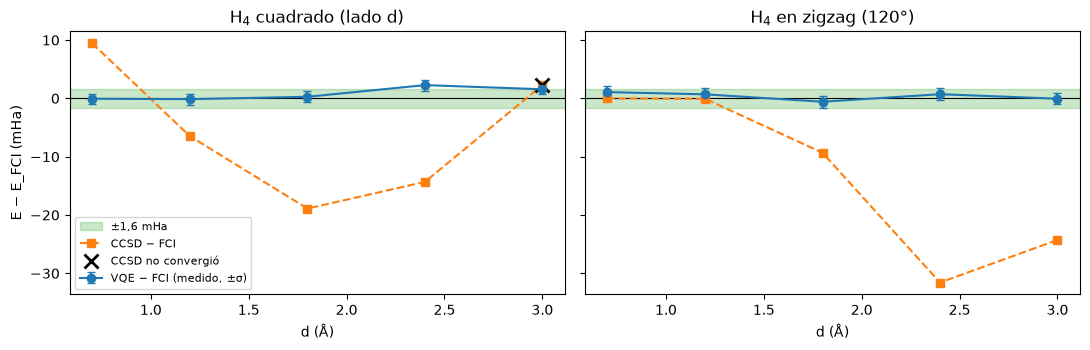

,shape,d,E_vqe,sigma,err_vqe_mHa,err_ccsd_mHa,ccsd_converged,beats_ccsd,cz_all,cz_line
0,square,0.7,-1.539443,0.000897,-0.063288,9.444815,True,True,582,1648
1,square,1.2,-1.967682,0.000951,-0.132350,-6.495924,True,True,582,1648
2,square,1.8,-1.917782,0.000930,0.271720,-18.895474,True,True,582,1648
3,square,2.4,-1.873569,0.000928,2.272280,-14.323018,True,True,582,1648
4,square,3.0,-1.865936,0.000863,1.559418,2.283375,False,False,582,1648
5,zigzag,0.7,-2.043068,0.000997,1.073715,-0.000873,True,False,582,1648
6,zigzag,1.2,-2.089390,0.001129,0.694105,-0.072615,True,False,582,1648
7,zigzag,1.8,-1.924090,0.001044,-0.578871,-9.336630,True,True,582,1648
8,zigzag,2.4,-1.873919,0.000983,0.713235,-31.581302,True,True,582,1648
9,zigzag,3.0,-1.867346,0.000983,-0.054855,-24.278063,True,True,582,1648


In [20]:
import pandas as pd, matplotlib.pyplot as plt
from h4vqe import config
from h4vqe.geometry import scan_geometry
from h4vqe.hamiltonian import ZIGZAG_ANGLE
GEO_D = [0.7, 1.2, 1.8, 2.4, 3.0]
GEO_SHOTS = 2_000_000   # σ ≈ 1,4 mHa por punto
geo = pd.DataFrame(scan_geometry("square", GEO_D, GEO_SHOTS) + scan_geometry("zigzag", GEO_D, GEO_SHOTS))
geo["beats_ccsd"] = geo.err_vqe_mHa.abs() + 1e3 * geo.sigma < geo.err_ccsd_mHa.abs()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, shape, title in zip(axs, ["square", "zigzag"], ["H$_4$ cuadrado (lado d)", f"H$_4$ en zigzag ({ZIGZAG_ANGLE:.0f}°)"]):
    g = geo[geo["shape"] == shape]
    a.axhspan(-1e3 * config.CHEM_ACC, 1e3 * config.CHEM_ACC, color="tab:green", alpha=0.25, label="±1,6 mHa")
    a.axhline(0, color="k", lw=0.8)
    a.errorbar(g.d, g.err_vqe_mHa, yerr=1e3 * g.sigma, fmt="o-", capsize=3, label="VQE − FCI (medido, ±σ)")
    a.plot(g.d, g.err_ccsd_mHa, "s--", color="tab:orange", label="CCSD − FCI")
    bad = g[~g.ccsd_converged]
    a.plot(bad.d, bad.err_ccsd_mHa, "x", color="k", ms=10, mew=2, label="CCSD no convergió")
    a.set_title(title); a.set_xlabel("d (Å)")
axs[0].set_ylabel("E − E_FCI (mHa)"); axs[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
geo[["shape", "d", "E_vqe", "sigma", "err_vqe_mHa", "err_ccsd_mHa", "ccsd_converged", "beats_ccsd", "cz_all", "cz_line"]]